# Predicción de suscripción a depósitos a plazo
### Proyecto final de Ciencia de Datos · Bank Marketing (UCI)

Se predice si un cliente contratará un **depósito a plazo** después de una campaña de telemarketing de un banco portugués. Se comparan un **clasificador bayesiano**, una **máquina de soporte vectorial** y una **red neuronal (MLP)** contra una **regresión logística** de referencia.

El trabajo sigue las fases de la metodología **CRISP-DM**:

| Fase | Sección |
|---|---|
| Entendimiento del negocio | 1 |
| Entendimiento de los datos | 2 |
| Preparación de los datos | 3 |
| Modelado | 4 |
| Evaluación | 5 – 7 |
| Conclusiones | 8 |

> Ejecutar con **Kernel → Restart & Run All**. Las figuras se guardan en `figuras/` y las tablas en `resultados/`. Tiempo aproximado: 3 a 6 minutos.

In [1]:
# ===== Librerías =====
import os, random, time, warnings, platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from scipy import stats

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder, KBinsDiscretizer, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import CategoricalNB, GaussianNB
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.base import clone
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score, confusion_matrix,
                             roc_curve, precision_recall_curve)

warnings.filterwarnings("ignore")

# ===== Reproducibilidad =====
SEMILLA = 7
random.seed(SEMILLA)
np.random.seed(SEMILLA)
os.environ["PYTHONHASHSEED"] = str(SEMILLA)

os.makedirs("figuras", exist_ok=True)
os.makedirs("resultados", exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook", font_scale=0.9)
plt.rcParams.update({"savefig.dpi": 300, "axes.spines.top": False, "axes.spines.right": False})
COL_Y = {"No": "#2a78d6", "Sí": "#eb6834"}
COL_M = {"Regresión logística": "#2a78d6", "Naive Bayes": "#eb6834", "SVM": "#1baf7a", "MLP": "#eda100"}
LS_M = {"Regresión logística": "-", "Naive Bayes": "--", "SVM": "-.", "MLP": ":"}

def guardar_fig(nombre):
    plt.tight_layout()
    plt.savefig(f"figuras/{nombre}.png", bbox_inches="tight")

for lib, v in [("Python", platform.python_version()), ("numpy", np.__version__), ("pandas", pd.__version__),
               ("scikit-learn", sklearn.__version__), ("matplotlib", matplotlib.__version__), ("seaborn", sns.__version__)]:
    print(f"{lib:13s} {v}")

Python        3.13.18
numpy         2.5.3
pandas        3.0.5
scikit-learn  1.9.1
matplotlib    3.11.2
seaborn       0.13.2


## 1. Entendimiento del negocio

Un banco portugués hizo campañas de telemarketing entre mayo de 2008 y noviembre de 2010 para ofrecer depósitos a plazo. Llamar a todos los clientes es caro y molesto, así que el objetivo es **priorizar a quién llamar**: un modelo que identifique a los clientes con mayor probabilidad de aceptar.

- **Clase positiva (1):** el cliente **sí** contrata el depósito (`y = "yes"`).
- **Costo de los errores:** un falso negativo es un cliente interesado al que no se llama (venta perdida); un falso positivo es una llamada que no termina en venta (costo de operación). Ninguno es catastrófico, por eso usamos **F1** como métrica principal y además reportamos la curva **precisión-recall**, más informativa que la ROC cuando la clase positiva es minoritaria.

## 2. Entendimiento de los datos

Archivo `datos/bank-full.csv` del UCI Machine Learning Repository (Moro, Cortez y Rita). Contiene 45 211 contactos y 16 variables de entrada:

| Grupo | Variables |
|---|---|
| Datos del cliente | `age`, `job`, `marital`, `education`, `default`, `balance`, `housing`, `loan` |
| Último contacto | `contact`, `day`, `month`, `duration` |
| Historial de campañas | `campaign`, `pdays`, `previous`, `poutcome` |
| Objetivo | `y` (yes / no) |

In [2]:
datos = pd.read_csv("datos/bank-full.csv", sep=";")
print("Registros y columnas:", datos.shape)
datos.head()

Registros y columnas: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [3]:
VAR_NUM = ["age", "balance", "day", "duration", "campaign", "pdays", "previous"]
VAR_CAT = ["job", "marital", "education", "default", "housing", "loan", "contact", "month", "poutcome"]

print("Valores faltantes (NaN):", int(datos.isna().sum().sum()))
print("Filas duplicadas:", int(datos.duplicated().sum()))
print("\nProporción de 'unknown' por variable categórica:")
desconocidos = pd.Series({c: (datos[c] == "unknown").mean() for c in VAR_CAT})
print((desconocidos[desconocidos > 0] * 100).round(1).astype(str) + " %")

Valores faltantes (NaN): 0


Filas duplicadas: 0

Proporción de 'unknown' por variable categórica:
job           0.6 %
education     4.1 %
contact      28.8 %
poutcome     81.7 %
dtype: str


In [4]:
datos[VAR_NUM].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.94,10.62,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.27,3044.77,-8019.0,72.0,448.0,1428.0,102127.0
day,45211.0,15.81,8.32,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.16,257.53,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.76,3.10,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.20,100.13,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.58,2.30,0.0,0.0,0.0,0.0,275.0


### 2.1 Desbalance de clases

    clientes     %
y                 
No     39922  88.3
Sí      5289  11.7


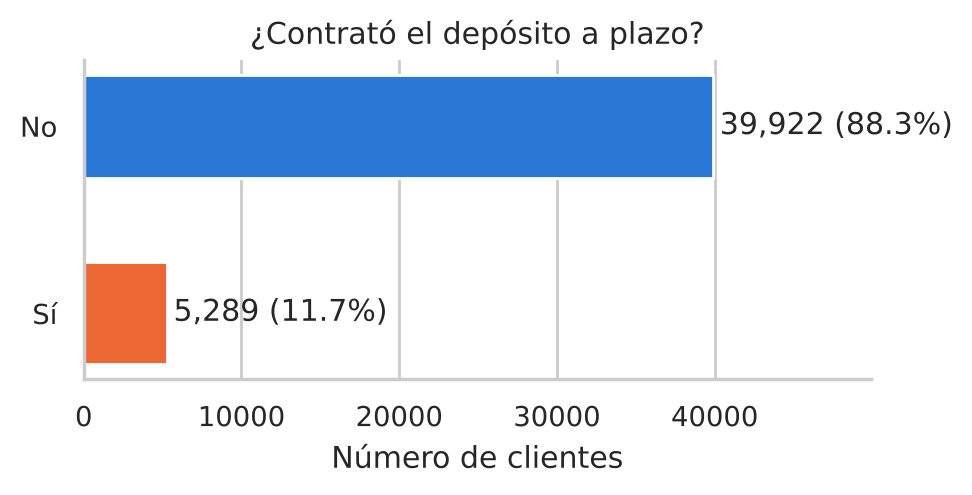

In [5]:
y_txt = datos["y"].map({"yes": "Sí", "no": "No"})
conteo = y_txt.value_counts()
print(pd.DataFrame({"clientes": conteo, "%": (conteo / len(datos) * 100).round(2)}))

fig, ax = plt.subplots(figsize=(5, 2.6))
ax.barh(conteo.index[::-1], conteo.values[::-1], color=[COL_Y[k] for k in conteo.index[::-1]], height=0.55)
for i, (k, v) in enumerate(conteo[::-1].items()):
    ax.text(v + 400, i, f"{v:,} ({v / len(datos):.1%})", va="center")
ax.set_xlim(0, conteo.max() * 1.25)
ax.set_xlabel("Número de clientes")
ax.set_title("¿Contrató el depósito a plazo?")
ax.grid(axis="y", visible=False)
guardar_fig("fig01_desbalance")
plt.show()

**Interpretación.** Solo el **11.7 %** de los clientes contrató el depósito (5 289 de 45 211). El desbalance es fuerte: un modelo que siempre responda "no" tendría **88.3 % de exactitud** sin servir para nada. Por eso la exactitud no se usa como métrica principal, y por eso la partición es estratificada.

### 2.2 Variables numéricas

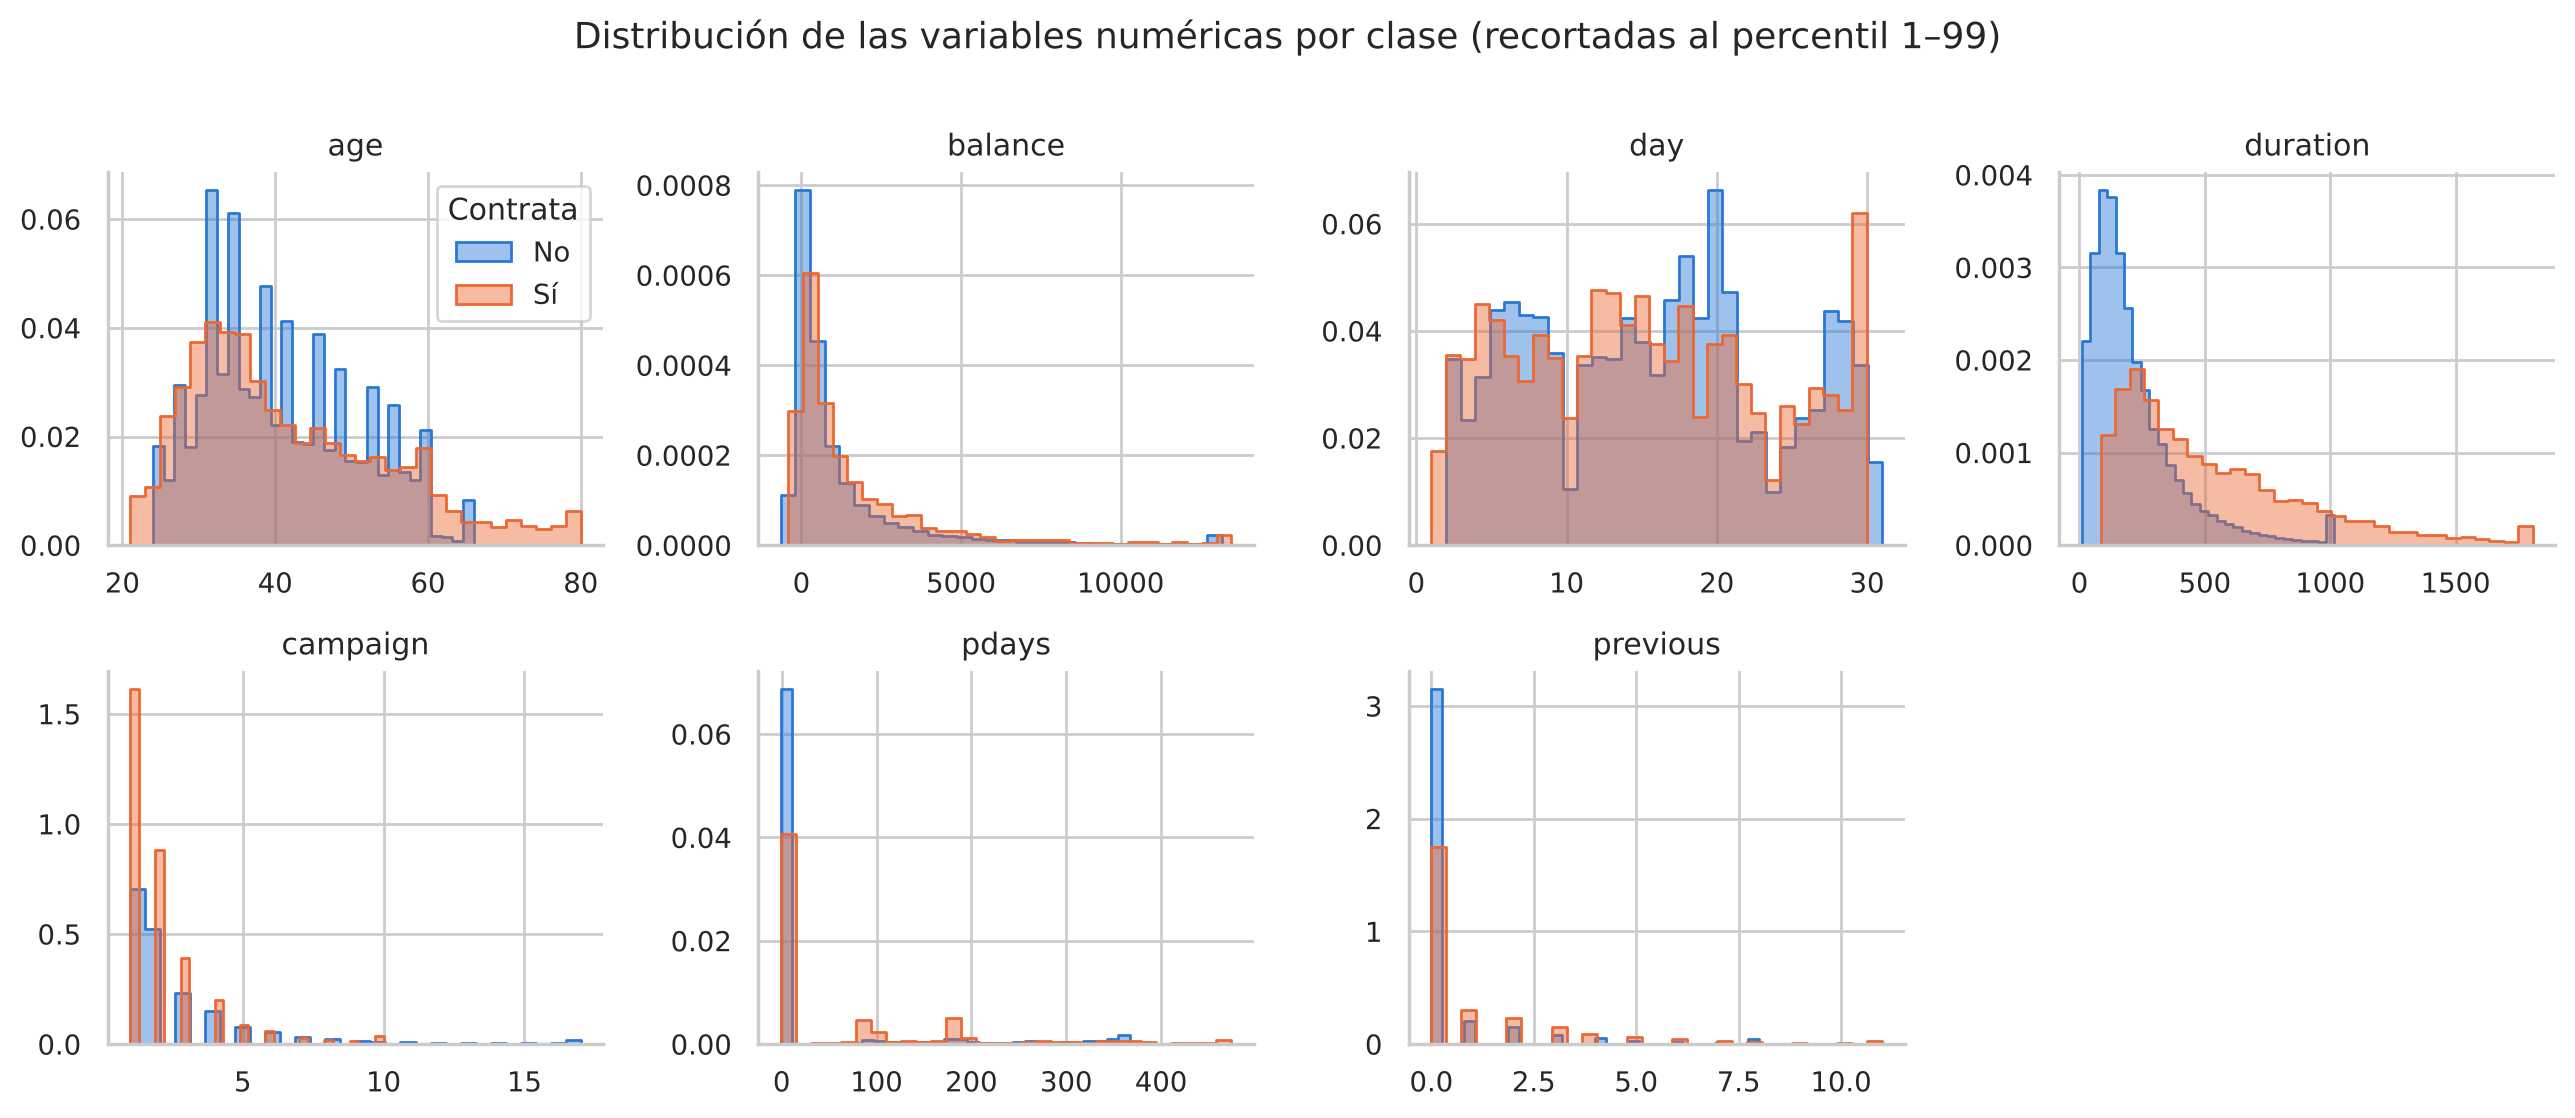

Asimetría:
previous    41.85
balance      8.36
campaign     4.90
duration     3.14
pdays        2.62
age          0.68
day          0.09
dtype: float64

Clientes nunca contactados antes (pdays = -1): 81.7%


In [6]:
fig, axes = plt.subplots(2, 4, figsize=(13, 5.5))
for ax, v in zip(axes.ravel(), VAR_NUM):
    for k in ["No", "Sí"]:
        vals = datos.loc[y_txt == k, v]
        lim = vals.quantile([0.01, 0.99]).values
        sns.histplot(vals.clip(*lim), ax=ax, stat="density", bins=30, color=COL_Y[k],
                     alpha=0.45, label=k, element="step")
    ax.set_title(v); ax.set_xlabel(""); ax.set_ylabel("")
axes[0, 0].legend(title="Contrata")
axes[1, 3].axis("off")
fig.suptitle("Distribución de las variables numéricas por clase (recortadas al percentil 1–99)", y=1.01)
guardar_fig("fig02_numericas")
plt.show()

print("Asimetría:")
print(datos[VAR_NUM].skew().round(2).sort_values(ascending=False))
print(f"\nClientes nunca contactados antes (pdays = -1): {(datos['pdays'] == -1).mean():.1%}")

**Interpretación.**
- `duration` es la variable que más separa las clases: las llamadas largas casi siempre terminan en contratación. Pero esto es consecuencia de la decisión del cliente, no una causa que se conozca de antemano (ver sección 3).
- `previous`, `balance` y `campaign` tienen **asimetrías extremas** (41.9, 8.4 y 4.9): la mayoría de los valores son pequeños y hay unos pocos muy grandes. Esto afecta a los modelos basados en distancias y es otra razón para discretizar las numéricas en Naive Bayes.
- El **81.7 %** de los clientes nunca había sido contactado (`pdays = −1`). Ese −1 es un código, no una cantidad de días.
- Los clientes contactados muchas veces en la campaña actual (`campaign` alto) contratan **menos**: insistir no ayuda.

### 2.3 Variables categóricas: tasa de éxito por categoría

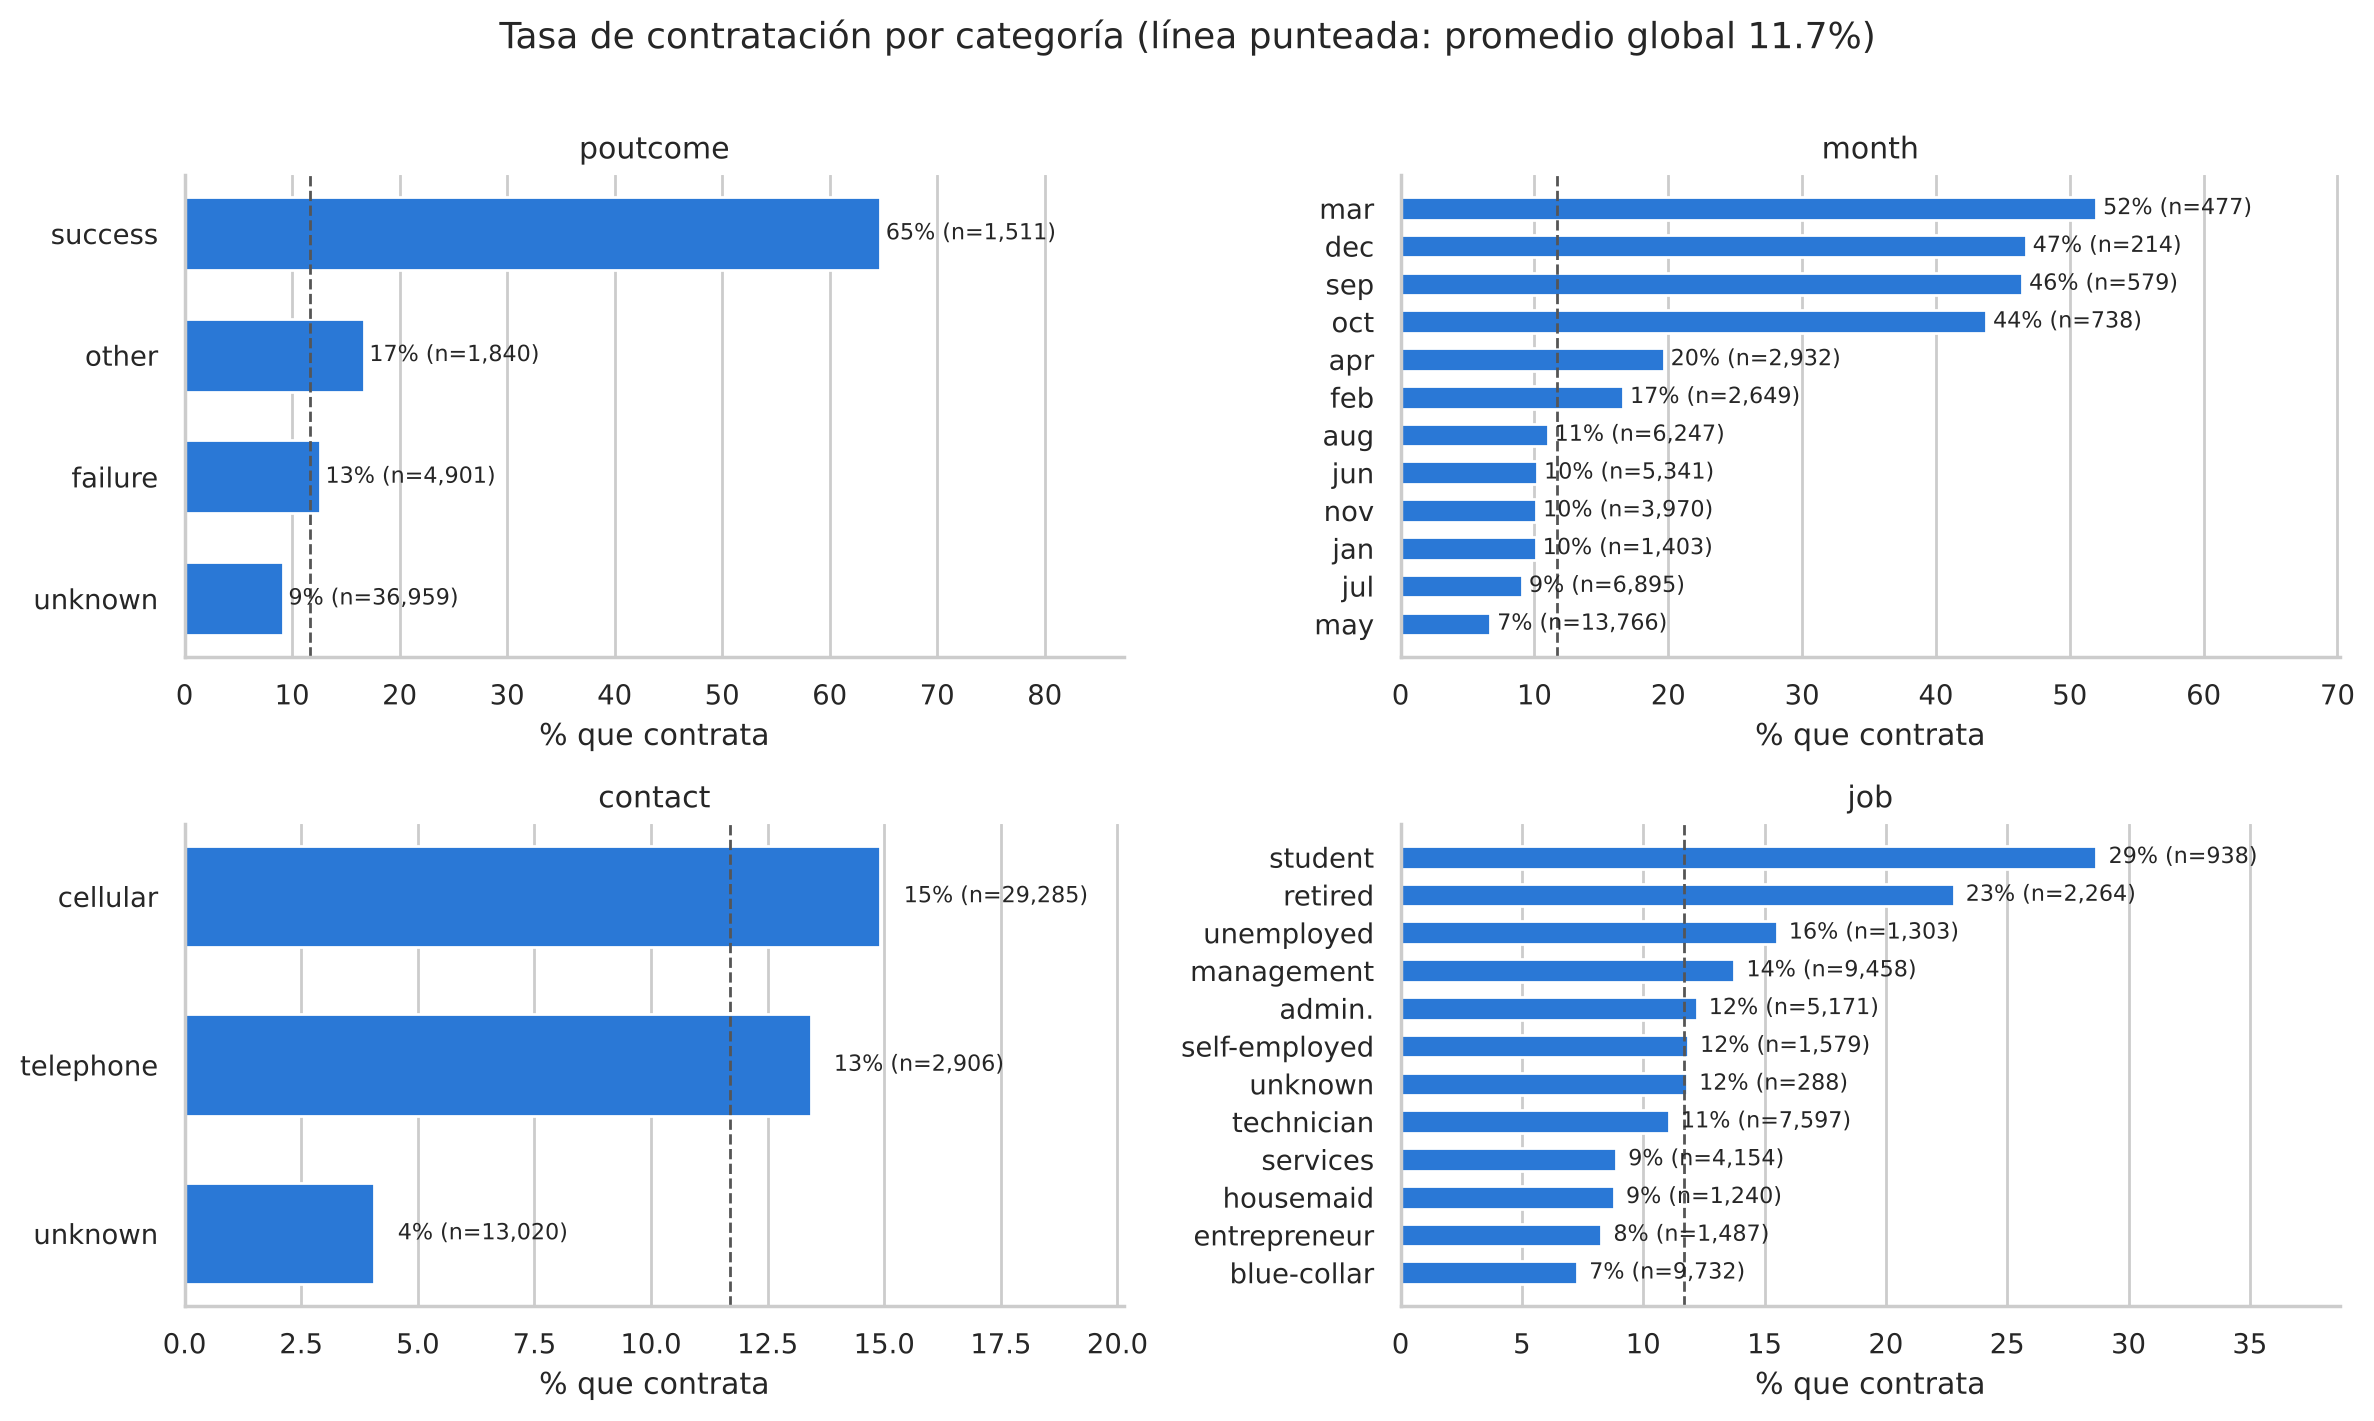

In [7]:
tasa_global = (datos["y"] == "yes").mean()
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, v in zip(axes.ravel(), ["poutcome", "month", "contact", "job"]):
    t = datos.groupby(v)["y"].apply(lambda s: (s == "yes").mean()).sort_values()
    n = datos[v].value_counts()[t.index]
    ax.barh(t.index, t.values * 100, color="#2a78d6", height=0.6)
    for i, (cat, val) in enumerate(t.items()):
        ax.text(val * 100 + 0.5, i, f"{val:.0%} (n={n[cat]:,})", va="center", fontsize=8)
    ax.axvline(tasa_global * 100, color="#555", ls="--", lw=1)
    ax.set_title(v); ax.set_xlabel("% que contrata"); ax.set_xlim(0, max(t.values) * 100 * 1.35)
    ax.grid(axis="y", visible=False)
fig.suptitle(f"Tasa de contratación por categoría (línea punteada: promedio global {tasa_global:.1%})", y=1.01)
guardar_fig("fig03_categoricas")
plt.show()

**Interpretación.**
- **`poutcome` es la variable más informativa:** el **65 %** de los clientes que aceptaron en una campaña anterior vuelve a aceptar, contra el 9 % de los que nunca fueron contactados.
- **`month`:** marzo, septiembre, octubre y diciembre tienen tasas de 44 % a 52 %, pero con pocas llamadas. Mayo concentra la mayor cantidad de llamadas (13 766) con la peor tasa (7 %). Esto sugiere que en los meses de campaña masiva se llama a clientes menos selectos.
- **`contact = unknown`** tiene solo 4 % de éxito, muy por debajo de celular (15 %).
- Por ocupación, estudiantes (29 %) y jubilados (23 %) contratan mucho más que obreros (*blue-collar*, 7 %).

### 2.4 Correlaciones y asociación con la clase

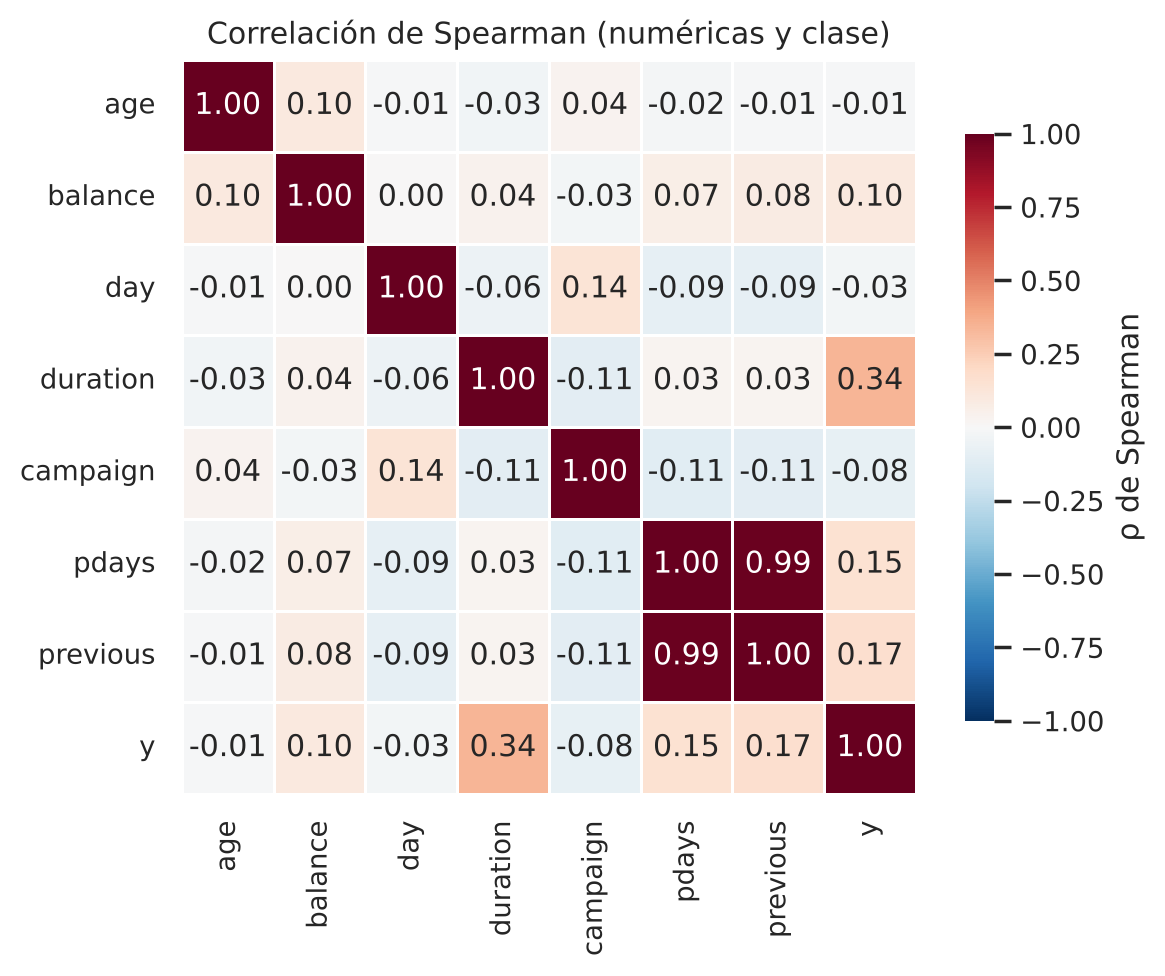

V de Cramér con la clase:
poutcome     0.312
month        0.260
contact      0.151
housing      0.139
job          0.136
education    0.073
loan         0.068
marital      0.066
default      0.022
dtype: float64


In [8]:
num_y = datos[VAR_NUM].copy()
num_y["y"] = (datos["y"] == "yes").astype(int)
corr = num_y.corr(method="spearman")
fig, ax = plt.subplots(figsize=(6.2, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0, square=True,
            linewidths=0.5, cbar_kws={"shrink": 0.8, "label": "ρ de Spearman"}, ax=ax)
ax.set_title("Correlación de Spearman (numéricas y clase)")
ax.grid(False)
guardar_fig("fig04_correlacion")
plt.show()

# Asociación de cada categórica con la clase: V de Cramér
def v_cramer(a, b):
    tabla = pd.crosstab(a, b)
    chi2 = stats.chi2_contingency(tabla, correction=False)[0]
    n = tabla.values.sum()
    return np.sqrt(chi2 / (n * (min(tabla.shape) - 1)))

cramer = pd.Series({c: v_cramer(datos[c], datos["y"]) for c in VAR_CAT}).sort_values(ascending=False)
print("V de Cramér con la clase:")
print(cramer.round(3))

**Interpretación.**
- Entre las numéricas, la única asociación fuerte es **`pdays`–`previous` (ρ = 0.99)**: las dos describen el historial de contactos previos y son casi redundantes.
- Con la clase, `duration` es la más correlacionada (0.34), lo cual confirma su fuga de información. Le siguen `previous` (0.17) y `pdays` (0.15). Las demás numéricas casi no se relacionan con la clase.
- Entre las categóricas (V de Cramér), las más asociadas con la clase son `poutcome` (0.31), `month` (0.26) y `contact` (0.15).
- En general, ninguna variable por sí sola separa bien las clases. Es de esperar un problema **difícil**, con métricas mucho más modestas que en conjuntos "limpios".

## 3. Preparación de los datos

**Decisiones:**
1. **Se elimina `duration`.** La documentación del dataset advierte que esta variable determina casi por completo el resultado (si dura 0 segundos, la respuesta es "no") y que **solo se conoce después de la llamada**. Usarla sería una fuga de información: el modelo no serviría para decidir a quién llamar.
2. **`unknown` se conserva como categoría.** En `poutcome` el 82 % de los valores son `unknown`, porque son clientes nunca contactados antes, y en `contact` el 29 %. No son errores de captura: la ausencia de información es en sí misma informativa.
3. **Nueva variable `contactado_antes`** = 1 si `pdays ≠ −1`. El valor −1 es un código de "nunca contactado", no una cantidad de días.
4. **Codificación y escalado** dentro de un `ColumnTransformer`: one-hot para las categóricas y estandarización para las numéricas. Todo va dentro de un `Pipeline`, así que se ajusta **solo con los datos de entrenamiento** de cada fold.
5. **Partición estratificada 60 / 20 / 20** (entrenamiento / validación / prueba) con semilla fija. La validación se usa para **elegir el umbral de decisión** de cada modelo.

In [9]:
X = datos.drop(columns=["y", "duration"]).copy()
X["contactado_antes"] = (X["pdays"] != -1).astype(int)
y = (datos["y"] == "yes").astype(int)

NUM = ["age", "balance", "day", "campaign", "pdays", "previous", "contactado_antes"]
CAT = VAR_CAT

X_ent, X_tmp, y_ent, y_tmp = train_test_split(X, y, test_size=0.40, stratify=y, random_state=SEMILLA)
X_val, X_pru, y_val, y_pru = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEMILLA)

particion = pd.DataFrame({"registros": [len(y_ent), len(y_val), len(y_pru)],
                          "% sí": [y_ent.mean() * 100, y_val.mean() * 100, y_pru.mean() * 100]},
                         index=["Entrenamiento", "Validación", "Prueba"]).round(2)
particion

,registros,% sí
Entrenamiento,27126,11.7
Validación,9042,11.7
Prueba,9043,11.7


In [10]:
# Preprocesamiento para modelos que usan distancias o gradientes (RL, SVM, MLP)
def prep_escalado():
    return ColumnTransformer([
        ("num", StandardScaler(), NUM),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)])

# Preprocesamiento para Naive Bayes categórico: numéricas → intervalos, categóricas → códigos
def prep_categorico(n_bins=10):
    return ColumnTransformer([
        ("num", KBinsDiscretizer(n_bins=n_bins, encode="ordinal", strategy="quantile", subsample=None), NUM),
        ("cat", OrdinalEncoder(), CAT)])

n_col = prep_escalado().fit(X_ent).transform(X_ent.head()).shape[1]
print("Columnas después de one-hot + escalado:", n_col)

Columnas después de one-hot + escalado: 51


## 4. Modelado

- **Búsqueda en malla** con validación cruzada estratificada de 5 folds sobre entrenamiento.
- **Métrica de selección: precisión promedio (AP, área bajo la curva precisión-recall).** No depende del umbral y es adecuada para clases desbalanceadas. El umbral se elige después, en validación.
- **Desbalance:** la regresión logística y la SVM usan `class_weight="balanced"`; el MLP y Naive Bayes compensan el desbalance con el ajuste del umbral.

In [11]:
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
busquedas, espacio, tiempos = {}, {}, {}

def ajustar(nombre, pipe, malla, Xa=None, ya=None, cv=cv5):
    Xa = X_ent if Xa is None else Xa
    ya = y_ent if ya is None else ya
    t0 = time.time()
    gs = GridSearchCV(pipe, malla, scoring="average_precision", cv=cv, n_jobs=-1, refit=True)
    gs.fit(Xa, ya)
    tiempos[nombre] = time.time() - t0
    i = gs.best_index_
    print(f"{nombre}: {len(gs.cv_results_['params'])} combinaciones, {tiempos[nombre]:.0f} s")
    print("  mejores:", {k.split('__')[-1]: v for k, v in gs.best_params_.items()})
    print(f"  AP en CV: {gs.cv_results_['mean_test_score'][i]:.4f} ± {gs.cv_results_['std_test_score'][i]:.4f}")
    return gs

### 4.1 Referencia: regresión logística

In [12]:
pipe = Pipeline([("prep", prep_escalado()),
                 ("modelo", LogisticRegression(class_weight="balanced", max_iter=3000, random_state=SEMILLA))])
malla = {"modelo__C": [0.001, 0.01, 0.1, 1, 10]}
busquedas["Regresión logística"] = ajustar("Regresión logística", pipe, malla)
espacio["Regresión logística"] = "C ∈ {0.001, 0.01, 0.1, 1, 10}; L2; class_weight = balanced"

Regresión logística: 5 combinaciones, 5 s
  mejores: {'C': 0.1}
  AP en CV: 0.4019 ± 0.0074


### 4.2 Clasificador bayesiano: Naive Bayes categórico

**¿Qué variante usar?** Los datos son **mixtos**: 9 variables categóricas y 7 numéricas con distribuciones muy sesgadas. `GaussianNB` supone normalidad en cada variable, cosa que no se cumple, y aplicarlo a columnas one-hot (0/1) no tiene sentido. Por eso elegimos **`CategoricalNB`**: las categóricas se usan tal cual y las numéricas se **discretizan en intervalos por cuantiles**, así no hay que suponer ninguna forma de distribución.

**Supuesto principal:** las variables son **independientes entre sí dada la clase**. Se ajustan el número de intervalos y el suavizado de Laplace `alpha`. Como comparación también se entrena `GaussianNB` sobre los datos escalados.

In [13]:
pipe = Pipeline([("prep", prep_categorico()), ("modelo", CategoricalNB())])
malla = {"prep__num__n_bins": [4, 6, 10, 15], "modelo__alpha": [0.1, 0.5, 1, 5]}
busquedas["Naive Bayes"] = ajustar("Naive Bayes", pipe, malla)
espacio["Naive Bayes"] = "CategoricalNB; intervalos ∈ {4, 6, 10, 15} × α ∈ {0.1, 0.5, 1, 5}"

# Comparación con la variante gaussiana
pipe_g = Pipeline([("prep", prep_escalado()), ("modelo", GaussianNB())])
gs_g = ajustar("Naive Bayes gaussiano (comparación)", pipe_g, {"modelo__var_smoothing": [1e-9, 1e-6, 1e-3, 1e-1]})

Naive Bayes: 16 combinaciones, 6 s
  mejores: {'alpha': 0.1, 'n_bins': 4}
  AP en CV: 0.3900 ± 0.0131


Naive Bayes gaussiano (comparación): 4 combinaciones, 2 s
  mejores: {'var_smoothing': 0.001}
  AP en CV: 0.3379 ± 0.0123


In [14]:
# ¿Se cumple la independencia? Correlaciones fuertes entre variables de entrada
cod = prep_categorico(10).fit_transform(X_ent)
cod = pd.DataFrame(cod, columns=NUM + CAT)
rho = cod.corr(method="spearman").abs()
pares = rho.where(np.triu(np.ones(rho.shape, dtype=bool), 1)).stack().dropna().sort_values(ascending=False)
print("Pares de variables más asociadas (|ρ| de Spearman sobre los códigos):")
print(pares.head(6).round(3))

Pares de variables más asociadas (|ρ| de Spearman sobre los códigos):
previous  poutcome    0.783
pdays     poutcome    0.722
          previous    0.528
age       marital     0.445
contact   month       0.321
          poutcome    0.278
dtype: float64


**Interpretación.**
- La elección de la variante se confirma: **CategoricalNB (AP = 0.390) supera claramente a GaussianNB (AP = 0.338).** El gaussiano supone normalidad en variables que son binarias (one-hot) o muy asimétricas.
- El mejor CategoricalNB usa **solo 4 intervalos** y poco suavizado (α = 0.1). Con más intervalos, cada uno tiene menos datos y la estimación se vuelve ruidosa.
- **El supuesto de independencia no se cumple:** `previous`, `pdays` y `poutcome` describen el mismo historial y tienen asociaciones de 0.53 a 0.78. Naive Bayes "cuenta tres veces" esa evidencia. Aun así, su AP queda cerca del de la regresión logística (0.390 contra 0.402), lo que muestra que el modelo es robusto para **ordenar** a los clientes aunque sus probabilidades estén sesgadas.

### 4.3 Máquina de soporte vectorial

La SVM con kernel RBF tiene un costo de entrenamiento que crece entre cuadrática y cúbicamente con el número de muestras. Con unas 27 000 muestras, cada ajuste tarda decenas de segundos, y una malla con validación cruzada no sería práctica en una laptop. Por eso:
1. La **búsqueda de hiperparámetros** se hace sobre una **submuestra estratificada de 6 000 registros** de entrenamiento, con 3 folds.
2. El **modelo final** se reentrena con los mejores hiperparámetros sobre **todo** el conjunto de entrenamiento.

Se prueban el kernel **lineal** (C) y el **RBF** (C y γ). Como puntaje se usa la función de decisión (distancia al hiperplano), que basta para calcular AP, ROC y el umbral.

In [15]:
X_sub, _, y_sub, _ = train_test_split(X_ent, y_ent, train_size=6000, stratify=y_ent, random_state=SEMILLA)
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEMILLA)
pipe = Pipeline([("prep", prep_escalado()),
                 ("modelo", SVC(class_weight="balanced", cache_size=1000, random_state=SEMILLA))])
gs_lin = ajustar("SVM lineal", pipe, {"modelo__kernel": ["linear"], "modelo__C": [0.001, 0.01, 0.1, 1]},
                 X_sub, y_sub, cv3)
gs_rbf = ajustar("SVM RBF", pipe, {"modelo__kernel": ["rbf"], "modelo__C": [0.1, 1, 10, 100],
                                   "modelo__gamma": [0.001, 0.01, 0.1, 1]}, X_sub, y_sub, cv3)
gs_svm = gs_rbf if gs_rbf.best_score_ >= gs_lin.best_score_ else gs_lin
print("\nKernel elegido:", gs_svm.best_params_["modelo__kernel"])
espacio["SVM"] = ("lineal: C ∈ {0.001, 0.01, 0.1, 1}; RBF: C ∈ {0.1, 1, 10, 100} × γ ∈ {0.001, 0.01, 0.1, 1}; "
                  "submuestra de 6 000, CV de 3 folds")

# Reentrenar con todo el conjunto de entrenamiento
t0 = time.time()
svm_final = clone(gs_svm.best_estimator_).fit(X_ent, y_ent)
print(f"Reentrenamiento con {len(y_ent):,} registros: {time.time() - t0:.0f} s")
busquedas["SVM"] = gs_svm

SVM lineal: 4 combinaciones, 8 s
  mejores: {'C': 1, 'kernel': 'linear'}
  AP en CV: 0.3566 ± 0.0198


SVM RBF: 16 combinaciones, 39 s
  mejores: {'C': 100, 'gamma': 0.001, 'kernel': 'rbf'}
  AP en CV: 0.3573 ± 0.0218

Kernel elegido: rbf


Reentrenamiento con 27,126 registros: 33 s


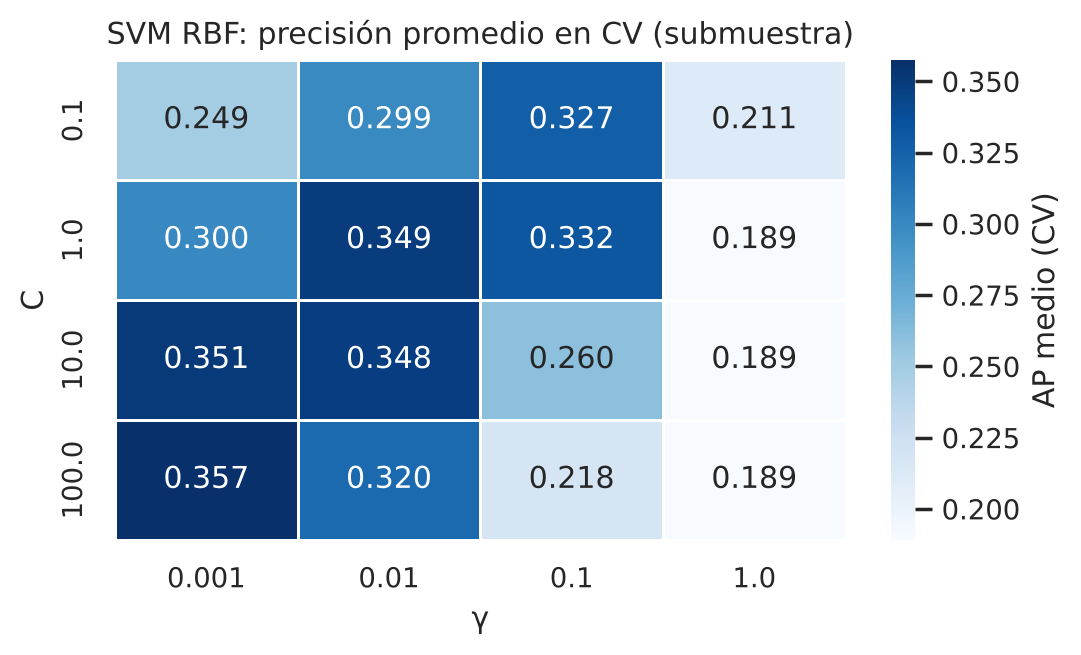

In [16]:
r = pd.DataFrame(gs_rbf.cv_results_)
mapa = r.pivot_table(index="param_modelo__C", columns="param_modelo__gamma", values="mean_test_score")
fig, ax = plt.subplots(figsize=(5.5, 3.4))
sns.heatmap(mapa, annot=True, fmt=".3f", cmap="Blues", linewidths=0.5, ax=ax, cbar_kws={"label": "AP medio (CV)"})
ax.set_xlabel("γ"); ax.set_ylabel("C"); ax.set_title("SVM RBF: precisión promedio en CV (submuestra)")
ax.grid(False)
guardar_fig("fig05_svm_malla")
plt.show()

**Interpretación.**
- Los mejores valores del kernel RBF son **C = 100 y γ = 0.001**: un γ muy pequeño hace que la frontera sea suave, casi lineal. Por eso el kernel RBF (AP = 0.357) y el lineal (AP = 0.357) quedan prácticamente empatados en la submuestra.
- Con γ ≥ 0.1, el AP cae a 0.19–0.33: cada vector de soporte solo influye en su vecindad inmediata y el modelo sobreajusta.
- El AP de la SVM en CV (0.357) es menor que el de la regresión logística (0.402), en parte porque se ajustó con **6 000 registros en lugar de 27 000**. Al reentrenar con todo el conjunto, su desempeño en validación y prueba mejora (sección 5).

### 4.4 Red neuronal: perceptrón multicapa

**Arquitectura:** la entrada tiene 52 columnas después de la codificación. Probamos redes de **una capa** (16 o 64 neuronas) y de **dos capas en embudo** (64 → 32), suficientes para capturar interacciones entre variables (por ejemplo, mes × tipo de contacto) sin volverse demasiado grandes para el volumen de datos. La salida es una neurona sigmoide; el optimizador es Adam.

**Contra el sobreajuste:**
- **Regularización L2** (`alpha`).
- **Detención temprana:** el 10 % del entrenamiento se separa como validación interna, y el ajuste se detiene si la métrica no mejora en 10 épocas.

In [17]:
pipe = Pipeline([("prep", prep_escalado()),
                 ("modelo", MLPClassifier(early_stopping=True, validation_fraction=0.10, n_iter_no_change=10,
                                          max_iter=300, batch_size=256, random_state=SEMILLA))])
malla = {"modelo__hidden_layer_sizes": [(16,), (64,), (64, 32)],
         "modelo__activation": ["relu", "tanh"],
         "modelo__alpha": [1e-4, 1e-2, 1],
         "modelo__learning_rate_init": [0.001, 0.01]}
busquedas["MLP"] = ajustar("MLP", pipe, malla)
espacio["MLP"] = ("capas ∈ {(16), (64), (64, 32)} × activación ∈ {ReLU, tanh} × α ∈ {1e-4, 1e-2, 1} × "
                  "tasa ∈ {0.001, 0.01}; detención temprana")

MLP: 36 combinaciones, 70 s
  mejores: {'activation': 'relu', 'alpha': 0.0001, 'hidden_layer_sizes': (64, 32), 'learning_rate_init': 0.01}
  AP en CV: 0.4290 ± 0.0084


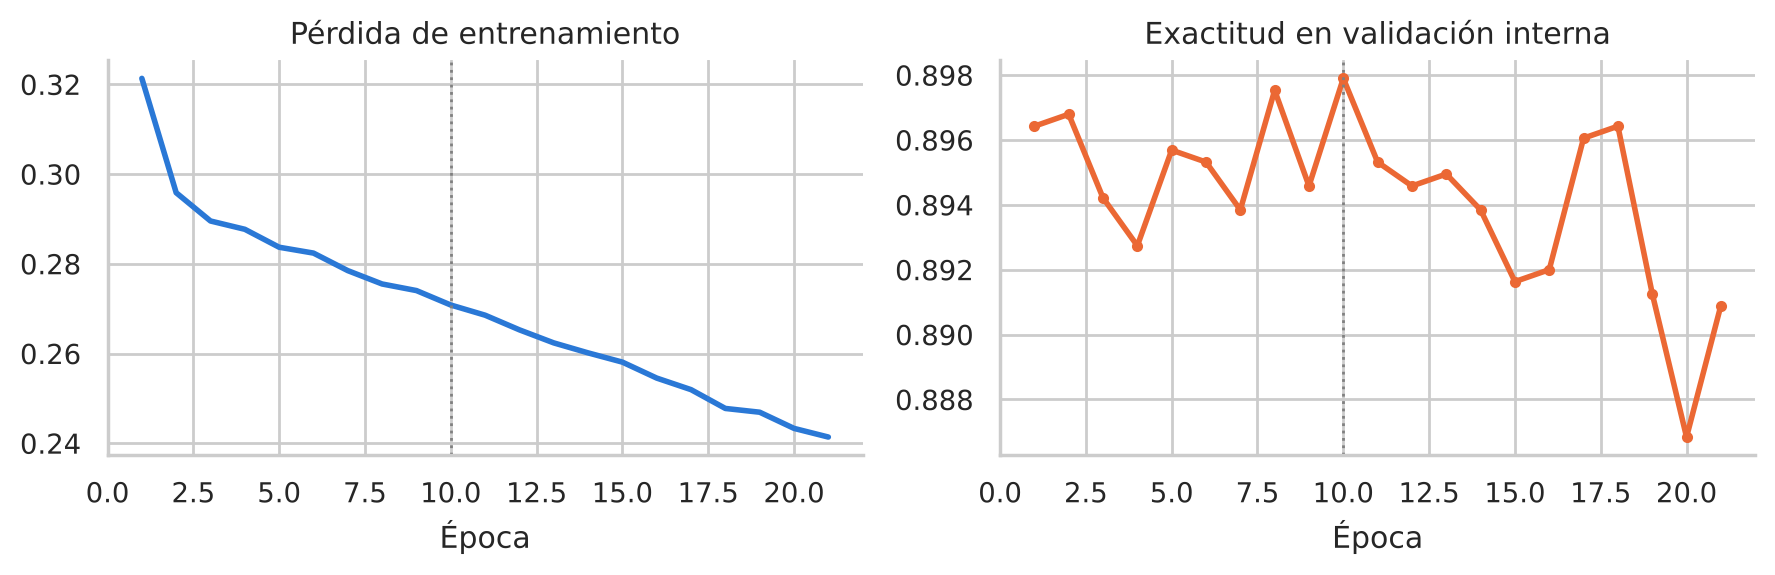

Épocas: 21; mejor época interna: 10


In [18]:
red = busquedas["MLP"].best_estimator_.named_steps["modelo"]
ep = np.arange(1, red.n_iter_ + 1)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9, 3))
a1.plot(ep, red.loss_curve_, color="#2a78d6", lw=2); a1.set_title("Pérdida de entrenamiento"); a1.set_xlabel("Época")
a2.plot(ep, red.validation_scores_, color="#eb6834", lw=2, marker="o", ms=3)
a2.set_title("Exactitud en validación interna"); a2.set_xlabel("Época")
mejor = int(np.argmax(red.validation_scores_)) + 1
for a in (a1, a2): a.axvline(mejor, color="gray", ls=":", lw=1)
guardar_fig("fig06_mlp_entrenamiento")
plt.show()
print(f"Épocas: {red.n_iter_}; mejor época interna: {mejor}")

### 4.5 Resumen del ajuste

In [19]:
otro_kernel = "SVM lineal" if gs_svm is gs_rbf else "SVM RBF"
t_tabla = {"Regresión logística": tiempos["Regresión logística"], "Naive Bayes": tiempos["Naive Bayes"],
           "SVM": tiempos["SVM RBF"] if gs_svm is gs_rbf else tiempos["SVM lineal"], "MLP": tiempos["MLP"],
           "SVM (otro kernel)": tiempos[otro_kernel], "NB gaussiano (comparación)": tiempos["Naive Bayes gaussiano (comparación)"]}
filas = []
for nombre, gs in list(busquedas.items()) + [("SVM (otro kernel)", gs_lin if gs_svm is gs_rbf else gs_rbf),
                                              ("NB gaussiano (comparación)", gs_g)]:
    i = gs.best_index_
    filas.append({"Modelo": nombre,
                  "Espacio de búsqueda": espacio.get(nombre, "—"),
                  "Combinaciones": len(gs.cv_results_["params"]),
                  "Mejores hiperparámetros": {k.split("__")[-1]: v for k, v in gs.best_params_.items()},
                  "AP CV media": round(gs.cv_results_["mean_test_score"][i], 4),
                  "AP CV desv.": round(gs.cv_results_["std_test_score"][i], 4),
                  "Tiempo (s)": round(t_tabla[nombre], 1)})
tabla_ajuste = pd.DataFrame(filas)
tabla_ajuste.to_csv("resultados/ajuste_hiperparametros.csv", index=False)
pd.set_option("display.max_colwidth", None)
tabla_ajuste

,Modelo,Espacio de búsqueda,Combinaciones,Mejores hiperparámetros,AP CV media,AP CV desv.,Tiempo (s)
0,Regresión logística,"C ∈ {0.001, 0.01, 0.1, 1, 10}; L2; class_weight = balanced",5,{'C': 0.1},0.4019,0.0074,5.4
1,Naive Bayes,"CategoricalNB; intervalos ∈ {4, 6, 10, 15} × α ∈ {0.1, 0.5, 1, 5}",16,"{'alpha': 0.1, 'n_bins': 4}",0.3900,0.0131,5.8
2,SVM,"lineal: C ∈ {0.001, 0.01, 0.1, 1}; RBF: C ∈ {0.1, 1, 10, 100} × γ ∈ {0.001, 0.01, 0.1, 1}; submuestra de 6 000, CV de 3 folds",16,"{'C': 100, 'gamma': 0.001, 'kernel': 'rbf'}",0.3573,0.0218,38.6
3,MLP,"capas ∈ {(16), (64), (64, 32)} × activación ∈ {ReLU, tanh} × α ∈ {1e-4, 1e-2, 1} × tasa ∈ {0.001, 0.01}; detención temprana",36,"{'activation': 'relu', 'alpha': 0.0001, 'hidden_layer_sizes': (64, 32), 'learning_rate_init': 0.01}",0.4290,0.0084,69.7
4,SVM (otro kernel),—,4,"{'C': 1, 'kernel': 'linear'}",0.3566,0.0198,7.8
5,NB gaussiano (comparación),—,4,{'var_smoothing': 0.001},0.3379,0.0123,1.8


### 4.6 Sensibilidad a los hiperparámetros

In [20]:
rm = pd.DataFrame(busquedas["MLP"].cv_results_)
rm["capas"] = rm["param_modelo__hidden_layer_sizes"].astype(str)
rm["activación"] = rm["param_modelo__activation"].astype(str)
arq_mlp = rm.pivot_table(index="capas", columns="activación", values="mean_test_score", aggfunc="max").round(4)
rn = pd.DataFrame(busquedas["Naive Bayes"].cv_results_)
bins_nb = rn.pivot_table(index="param_prep__num__n_bins", columns="param_modelo__alpha", values="mean_test_score").round(4)
bins_nb.index.name = "intervalos"; bins_nb.columns.name = "alpha"
arq_mlp.to_csv("resultados/mlp_arquitectura.csv"); bins_nb.to_csv("resultados/nb_intervalos_alpha.csv")
print("MLP: mejor AP en CV por arquitectura y activación"); print(arq_mlp)
print("\nNaive Bayes: AP en CV por número de intervalos y alpha"); print(bins_nb)

MLP: mejor AP en CV por arquitectura y activación
activación    relu    tanh
capas                     
(16,)       0.4197  0.4086
(64, 32)    0.4290  0.4195
(64,)       0.4164  0.4191

Naive Bayes: AP en CV por número de intervalos y alpha
alpha          0.1     0.5     1.0     5.0
intervalos                                
4           0.3900  0.3900  0.3900  0.3896
6           0.3687  0.3687  0.3686  0.3680
10          0.3821  0.3820  0.3819  0.3811
15          0.3783  0.3782  0.3781  0.3772


**Interpretación.**
- **MLP:** la red de dos capas (64 → 32) con ReLU fue la mejor (AP = 0.429). Las redes de una capa quedan entre 0.409 y 0.420. La capa adicional ayuda a capturar interacciones entre variables; ReLU supera a tanh en 2 de las 3 arquitecturas.
- **Naive Bayes:** el número de intervalos sí importa. Con 4 intervalos el AP es 0.390, y con 6 baja a 0.369. El suavizado α casi no influye (diferencias menores a 0.001), porque con 27 000 registros cada categoría tiene suficientes datos.

## 5. Evaluación: umbral de decisión y conjunto de prueba

Con 11.7 % de positivos, el umbral por defecto (0.5 de probabilidad) hace que algunos modelos casi nunca predigan "sí". Para cada modelo se elige el **umbral que maximiza F1 en el conjunto de validación** y luego se aplica **sin cambios** al conjunto de prueba. Así la prueba se usa una sola vez.

In [21]:
finales = {"Regresión logística": busquedas["Regresión logística"].best_estimator_,
           "Naive Bayes": busquedas["Naive Bayes"].best_estimator_,
           "SVM": svm_final,
           "MLP": busquedas["MLP"].best_estimator_}

def puntaje(modelo, Xd):
    if isinstance(modelo.steps[-1][1], SVC):
        return modelo.decision_function(Xd)
    return modelo.predict_proba(Xd)[:, 1]

s_val = {n: puntaje(m, X_val) for n, m in finales.items()}
s_pru = {n: puntaje(m, X_pru) for n, m in finales.items()}

umbrales, filas = {}, []
for n in finales:
    p, r, t = precision_recall_curve(y_val, s_val[n])
    f1 = 2 * p * r / np.where(p + r == 0, 1, p + r)
    k = int(np.nanargmax(f1[:-1]))
    umbrales[n] = t[k]
    defecto = 0.0 if n == "SVM" else 0.5
    filas.append({"Modelo": n, "Umbral por defecto": defecto,
                  "F1 val. (defecto)": f1_score(y_val, s_val[n] >= defecto),
                  "Umbral elegido": round(float(t[k]), 4), "F1 val. (elegido)": f1[k]})
tabla_umbral = pd.DataFrame(filas).set_index("Modelo").round(4)
tabla_umbral.to_csv("resultados/umbrales_validacion.csv")
tabla_umbral

,Umbral por defecto,F1 val. (defecto),Umbral elegido,F1 val. (elegido)
Modelo,,,,
Regresión logística,0.5,0.3774,0.6201,0.4351
Naive Bayes,0.5,0.3839,0.3596,0.4296
SVM,0.0,0.4173,0.5747,0.4534
MLP,0.5,0.3938,0.2446,0.4680


**Interpretación.** Ajustar el umbral mejora el F1 de validación en los cuatro modelos (de 0.38–0.42 a 0.43–0.47). Los umbrales elegidos tienen sentido:
- **Regresión logística (0.62):** con `class_weight="balanced"` el modelo infla las probabilidades de la clase minoritaria, así que el umbral sube por encima de 0.5.
- **MLP (0.24) y Naive Bayes (0.36):** se entrenaron sin pesos de clase y sus probabilidades reflejan la tasa real de 11.7 %. Por eso conviene bajar el umbral para no perder demasiados clientes interesados.
- **SVM (0.57):** su puntaje es una distancia al hiperplano, no una probabilidad; el umbral solo desplaza ligeramente la frontera.

In [22]:
pred = {n: (s_pru[n] >= umbrales[n]).astype(int) for n in finales}
filas = []
for n in finales:
    tn, fp, fn, tp = confusion_matrix(y_pru, pred[n]).ravel()
    filas.append({"Modelo": n,
                  "Exactitud": accuracy_score(y_pru, pred[n]),
                  "Exactitud balanceada": balanced_accuracy_score(y_pru, pred[n]),
                  "Precisión": precision_score(y_pru, pred[n]),
                  "Sensibilidad": recall_score(y_pru, pred[n]),
                  "F1": f1_score(y_pru, pred[n]),
                  "AUC-ROC": roc_auc_score(y_pru, s_pru[n]),
                  "AP": average_precision_score(y_pru, s_pru[n]),
                  "VP": tp, "FP": fp, "FN": fn, "VN": tn})
tabla_prueba = pd.DataFrame(filas).set_index("Modelo")
tabla_prueba.round(4).to_csv("resultados/metricas_prueba.csv")
print(f"Prueba: {len(y_pru):,} clientes, {y_pru.sum():,} positivos ({y_pru.mean():.1%})")
print(f"Exactitud de un modelo que siempre dice 'no': {1 - y_pru.mean():.4f}")
tabla_prueba.round(4)

Prueba: 9,043 clientes, 1,058 positivos (11.7%)
Exactitud de un modelo que siempre dice 'no': 0.8830


,Exactitud,Exactitud balanceada,Precisión,Sensibilidad,F1,AUC-ROC,AP,VP,FP,FN,VN
Modelo,,,,,,,,,,,
Regresión logística,0.8621,0.6854,0.4179,0.4546,0.4355,0.7681,0.4061,481,670,577,7315
Naive Bayes,0.8667,0.6650,0.4263,0.4017,0.4136,0.7607,0.3896,425,572,633,7413
SVM,0.8662,0.6946,0.4338,0.4707,0.4515,0.7781,0.4047,498,650,560,7335
MLP,0.8735,0.7135,0.4627,0.5047,0.4828,0.7856,0.4353,534,620,524,7365


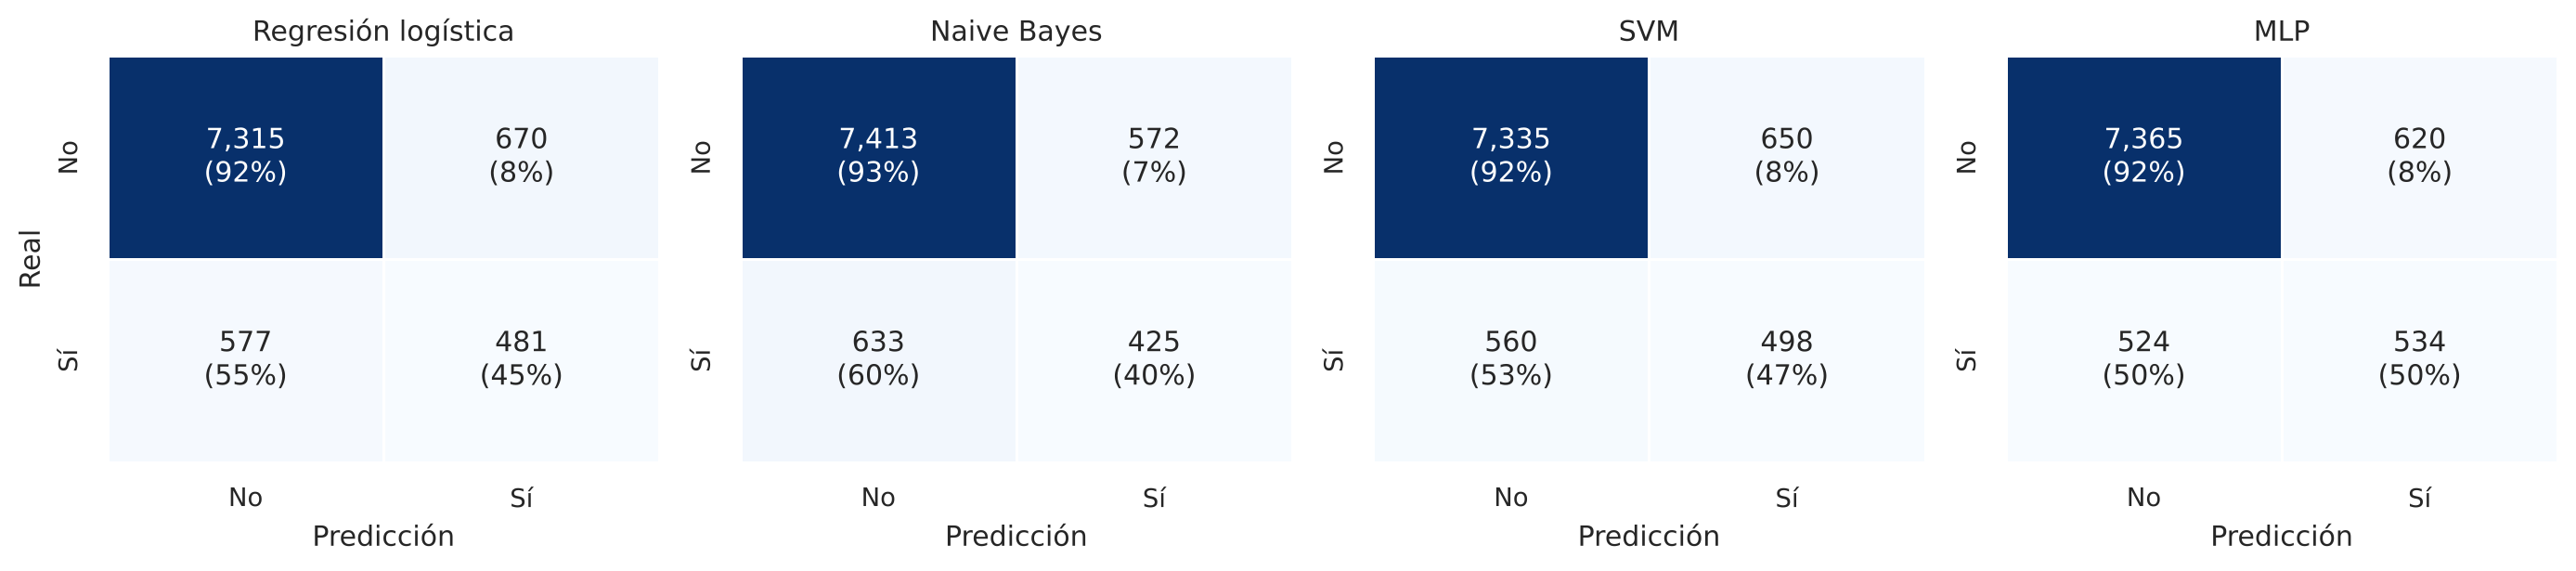

In [23]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.2))
for ax, n in zip(axes, finales):
    cm = confusion_matrix(y_pru, pred[n])
    etiquetas = np.array([[f"{v:,}\n({v / cm[i].sum():.0%})" for v in fila] for i, fila in enumerate(cm)])
    sns.heatmap(cm, annot=etiquetas, fmt="", cmap="Blues", cbar=False, ax=ax, linewidths=1, linecolor="white",
                xticklabels=["No", "Sí"], yticklabels=["No", "Sí"])
    ax.set_title(n); ax.set_xlabel("Predicción"); ax.grid(False)
axes[0].set_ylabel("Real")
guardar_fig("fig07_matrices_confusion")
plt.show()

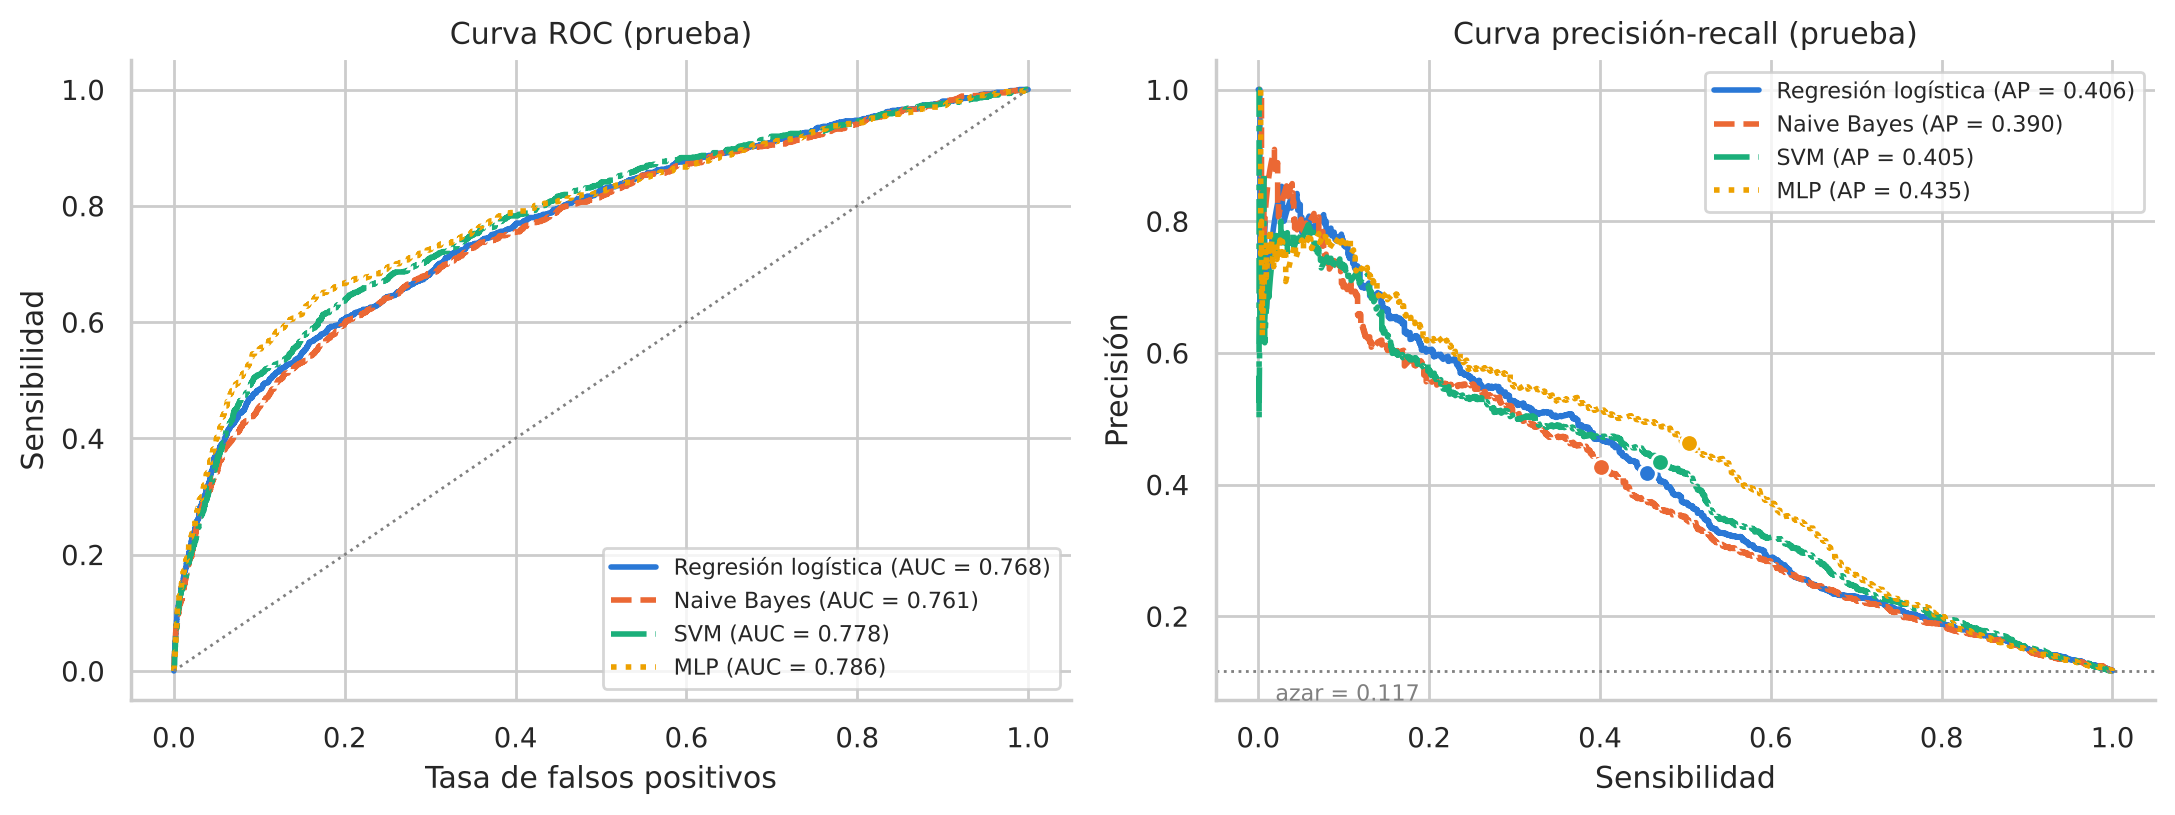

In [24]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.2))
for n in finales:
    f, t, _ = roc_curve(y_pru, s_pru[n])
    a1.plot(f, t, color=COL_M[n], ls=LS_M[n], lw=2, label=f"{n} (AUC = {roc_auc_score(y_pru, s_pru[n]):.3f})")
    p, r, _ = precision_recall_curve(y_pru, s_pru[n])
    a2.plot(r, p, color=COL_M[n], ls=LS_M[n], lw=2, label=f"{n} (AP = {average_precision_score(y_pru, s_pru[n]):.3f})")
    # punto de operación (umbral elegido)
    a2.scatter(recall_score(y_pru, pred[n]), precision_score(y_pru, pred[n]), color=COL_M[n], s=40, zorder=3,
               edgecolor="white")
a1.plot([0, 1], [0, 1], color="gray", ls=":", lw=1)
a1.set_xlabel("Tasa de falsos positivos"); a1.set_ylabel("Sensibilidad"); a1.set_title("Curva ROC (prueba)")
a1.legend(fontsize=8, loc="lower right")
a2.axhline(y_pru.mean(), color="gray", ls=":", lw=1)
a2.text(0.02, y_pru.mean() - 0.045, f"azar = {y_pru.mean():.3f}", ha="left", fontsize=8, color="gray")
a2.set_xlabel("Sensibilidad"); a2.set_ylabel("Precisión"); a2.set_title("Curva precisión-recall (prueba)")
a2.legend(fontsize=8, loc="upper right")
guardar_fig("fig08_roc_pr")
plt.show()

**Interpretación.**
- **Ningún modelo supera la exactitud trivial de 88.3 %** (todos quedan entre 86.2 % y 87.4 %). Era de esperar: al elegir el umbral por F1, los modelos aceptan más falsos positivos a cambio de encontrar clientes interesados. Por eso la exactitud no sirve aquí.
- **El MLP es el mejor en todas las métricas que importan:** F1 = 0.483, AP = 0.435, AUC = 0.786 y exactitud balanceada = 0.714. Encuentra a **la mitad de los clientes que contratan (sensibilidad 50.5 %)** con una precisión de 46.3 %. Eso es **4 veces mejor que llamar al azar**, donde la precisión sería 11.7 %.
- Le siguen la SVM (F1 = 0.451), la regresión logística (0.435) y Naive Bayes (0.414).
- En la curva precisión-recall, el MLP queda por encima de los demás en casi todo el rango de sensibilidades entre 0.2 y 0.7, que es la zona útil para el negocio.

### 5.1 Curva de ganancia acumulada
Para el banco, la pregunta práctica es: **si solo puedo llamar a una parte de los clientes, ¿a cuántos interesados encuentro?** La curva de ganancia ordena a los clientes de prueba según el puntaje del modelo, de mayor a menor, y muestra qué porcentaje de los que contratan se encuentra al llamar al primer *x* % de la lista.

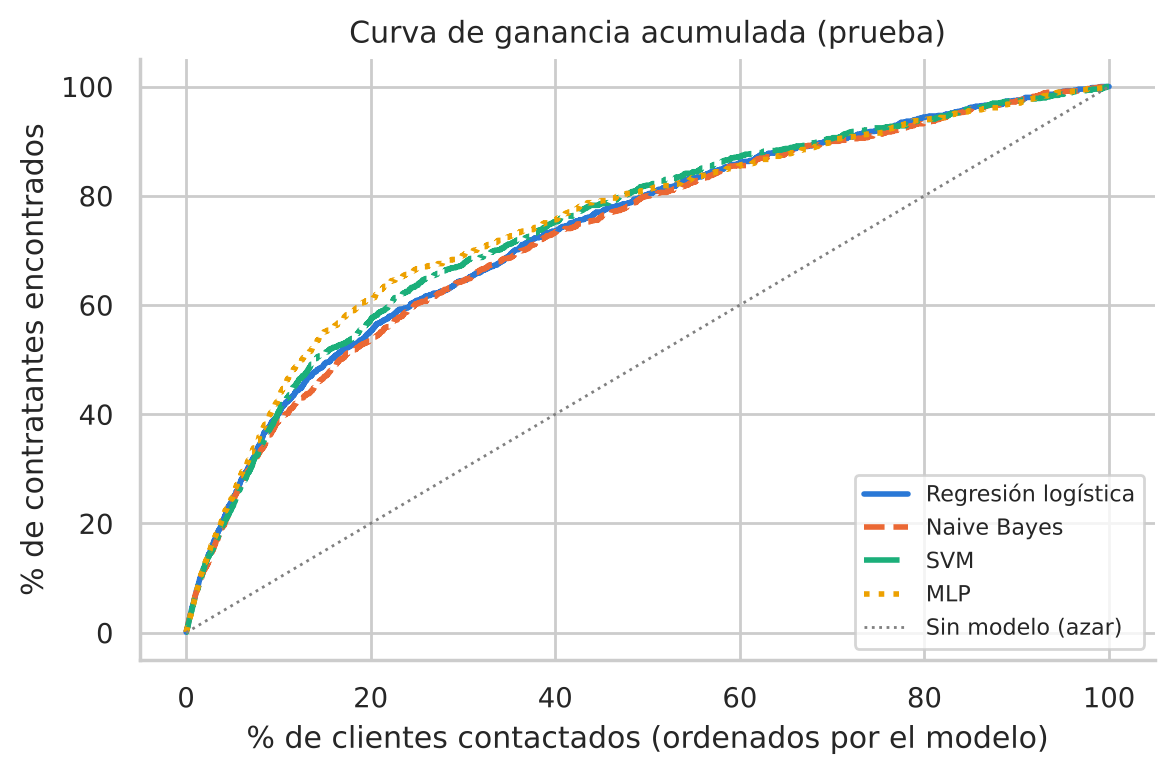

,Llamando al 10 %,Llamando al 20 %,Llamando al 30 %,Llamando al 50 %
Modelo,,,,
Regresión logística,40.2,55.3,64.5,80.2
Naive Bayes,38.7,53.5,64.5,80.0
SVM,40.4,57.3,67.4,81.9
MLP,42.9,61.1,69.1,81.0


In [25]:
def ganancia(y_real, puntaje):
    orden = np.argsort(-puntaje, kind="stable")
    acum = np.cumsum(np.asarray(y_real)[orden]) / np.sum(y_real)
    frac = np.arange(1, len(orden) + 1) / len(orden)
    return frac, acum

fig, ax = plt.subplots(figsize=(6, 4))
filas = []
for n in finales:
    fr, ac = ganancia(y_pru, s_pru[n])
    ax.plot(fr * 100, ac * 100, color=COL_M[n], ls=LS_M[n], lw=2, label=n)
    fila = {"Modelo": n}
    for pct in [10, 20, 30, 50]:
        k = int(len(fr) * pct / 100) - 1
        fila[f"Llamando al {pct} %"] = round(ac[k] * 100, 1)
    filas.append(fila)
ax.plot([0, 100], [0, 100], color="gray", ls=":", lw=1, label="Sin modelo (azar)")
ax.set_xlabel("% de clientes contactados (ordenados por el modelo)")
ax.set_ylabel("% de contratantes encontrados")
ax.set_title("Curva de ganancia acumulada (prueba)")
ax.legend(fontsize=8, loc="lower right")
guardar_fig("fig12_ganancia")
plt.show()
tabla_ganancia = pd.DataFrame(filas).set_index("Modelo")
tabla_ganancia.to_csv("resultados/ganancia_acumulada.csv")
tabla_ganancia

**Interpretación.**
- Sin modelo, llamar al 20 % de los clientes encontraría al 20 % de los interesados. **Con el MLP, llamar al 20 % de la lista encuentra al 61.1 %**, y llamar al 10 % encuentra al 42.9 %.
- El MLP domina en el tramo útil para el negocio (10 a 30 % de la cartera). Al llamar a la mitad de los clientes, todos los modelos encuentran alrededor del 80 % y las diferencias desaparecen.
- Esta curva permite al banco decidir cuántas llamadas hacer según su presupuesto: por ejemplo, con capacidad para llamar a 2 de cada 10 clientes, el modelo triplica los contratos respecto de una lista aleatoria.

## 6. Variabilidad de los resultados

Se usan tres fuentes de variabilidad:
1. **Entre folds:** la desviación estándar del AP en la validación cruzada del ajuste (sección 4.5).
2. **Entre semillas:** el MLP depende de la inicialización aleatoria de los pesos, así que se reentrena con **5 semillas distintas**.
3. **Remuestreo del conjunto de prueba (bootstrap):** 1 000 remuestras de prueba para obtener intervalos de confianza al 95 % de F1 y AP, y la **prueba de McNemar** para comparar los errores de cada par de modelos sobre los mismos clientes.

In [26]:
# (2) MLP con varias semillas
semillas = [7, 11, 23, 42, 99]
filas = []
for s in semillas:
    m = clone(finales["MLP"]).set_params(modelo__random_state=s).fit(X_ent, y_ent)
    sv, sp = m.predict_proba(X_val)[:, 1], m.predict_proba(X_pru)[:, 1]
    p, r, t = precision_recall_curve(y_val, sv)
    f1v = 2 * p * r / np.where(p + r == 0, 1, p + r)
    u = t[int(np.nanargmax(f1v[:-1]))]
    filas.append({"semilla": s, "AP prueba": average_precision_score(y_pru, sp),
                  "F1 prueba": f1_score(y_pru, sp >= u), "AUC prueba": roc_auc_score(y_pru, sp)})
semillas_mlp = pd.DataFrame(filas).set_index("semilla")
semillas_mlp.loc["media"] = semillas_mlp.mean()
semillas_mlp.loc["desv. est."] = semillas_mlp.iloc[:5].std(ddof=1)
semillas_mlp.round(4).to_csv("resultados/mlp_semillas.csv")
semillas_mlp.round(4)

,AP prueba,F1 prueba,AUC prueba
semilla,,,
7,0.4353,0.4828,0.7856
11,0.4318,0.4818,0.7889
23,0.4237,0.4779,0.7853
42,0.4331,0.4739,0.7885
99,0.4332,0.4692,0.7901
media,0.4314,0.4771,0.7877
desv. est.,0.0045,0.0057,0.0021


In [27]:
# (3) Bootstrap del conjunto de prueba
rng = np.random.default_rng(SEMILLA)
B = 1000
yv = y_pru.values
idx_b = [rng.integers(0, len(yv), len(yv)) for _ in range(B)]
boot = {n: {"F1": [], "AP": []} for n in finales}
for idx in idx_b:
    for n in finales:
        boot[n]["F1"].append(f1_score(yv[idx], pred[n][idx]))
        boot[n]["AP"].append(average_precision_score(yv[idx], s_pru[n][idx]))
filas = []
for n in finales:
    f1b, apb = np.array(boot[n]["F1"]), np.array(boot[n]["AP"])
    filas.append({"Modelo": n,
                  "F1": f"{tabla_prueba.loc[n, 'F1']:.3f} [{np.percentile(f1b, 2.5):.3f}, {np.percentile(f1b, 97.5):.3f}]",
                  "F1 desv. bootstrap": round(f1b.std(ddof=1), 4),
                  "AP": f"{tabla_prueba.loc[n, 'AP']:.3f} [{np.percentile(apb, 2.5):.3f}, {np.percentile(apb, 97.5):.3f}]",
                  "AP desv. bootstrap": round(apb.std(ddof=1), 4)})
tabla_boot = pd.DataFrame(filas).set_index("Modelo")
tabla_boot.to_csv("resultados/intervalos_bootstrap.csv")
tabla_boot

,F1,F1 desv. bootstrap,AP,AP desv. bootstrap
Modelo,,,,
Regresión logística,"0.435 [0.411, 0.463]",0.0136,"0.406 [0.376, 0.441]",0.0165
Naive Bayes,"0.414 [0.387, 0.441]",0.0139,"0.390 [0.360, 0.423]",0.0161
SVM,"0.451 [0.428, 0.478]",0.0132,"0.405 [0.374, 0.440]",0.0166
MLP,"0.483 [0.458, 0.508]",0.0131,"0.435 [0.404, 0.470]",0.0172


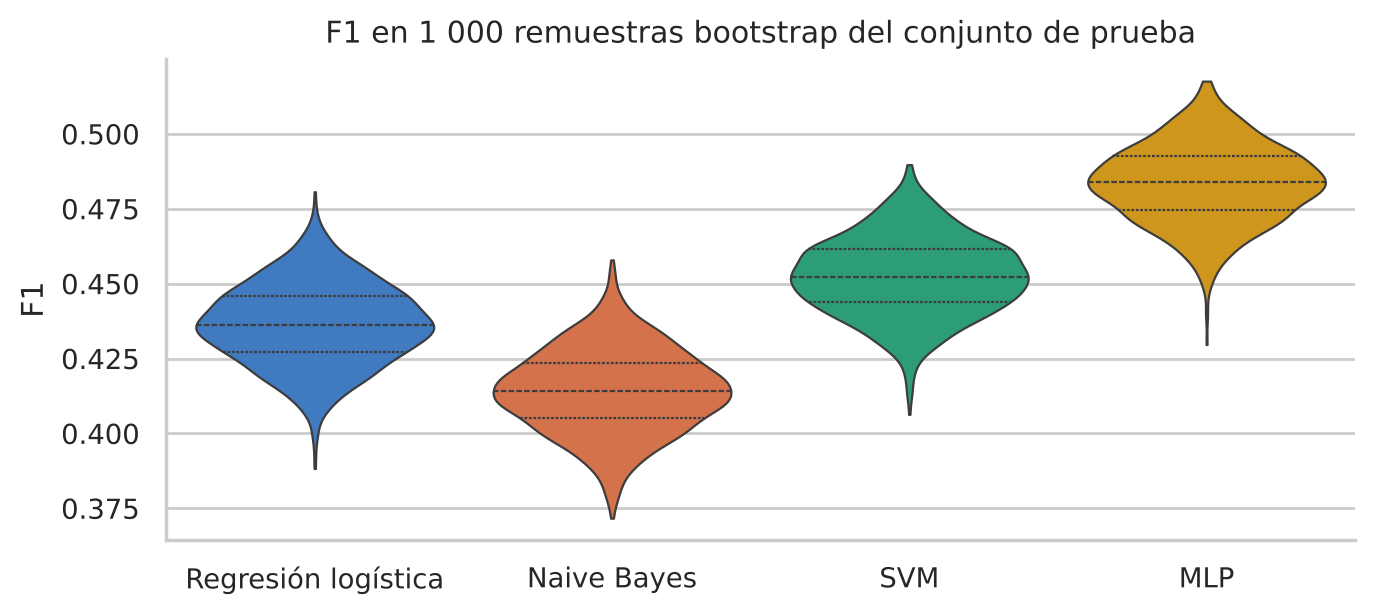

In [28]:
fig, ax = plt.subplots(figsize=(7, 3.2))
datos_b = pd.DataFrame({n: boot[n]["F1"] for n in finales}).melt(var_name="Modelo", value_name="F1")
sns.violinplot(data=datos_b, x="Modelo", y="F1", hue="Modelo", palette=COL_M, inner="quartile",
               cut=0, linewidth=0.8, ax=ax, legend=False)
ax.set_xlabel(""); ax.set_title("F1 en 1 000 remuestras bootstrap del conjunto de prueba")
guardar_fig("fig09_bootstrap_f1")
plt.show()

In [29]:
# Prueba de McNemar (con corrección de continuidad) entre cada par de modelos
from itertools import combinations
filas = []
nombres = list(finales)
for a, b in combinations(nombres, 2):
    ok_a, ok_b = pred[a] == yv, pred[b] == yv
    n01 = int(np.sum(ok_a & ~ok_b))   # a acierta, b falla
    n10 = int(np.sum(~ok_a & ok_b))   # a falla, b acierta
    chi2 = (abs(n01 - n10) - 1) ** 2 / (n01 + n10) if (n01 + n10) > 0 else 0.0
    p = stats.chi2.sf(chi2, 1)
    # diferencia de F1 con bootstrap pareado
    dif = np.array(boot[a]["F1"]) - np.array(boot[b]["F1"])
    filas.append({"Comparación": f"{a} vs {b}", "a acierta / b falla": n01, "a falla / b acierta": n10,
                  "χ²": round(chi2, 2), "p McNemar": p,
                  "ΔF1 (a − b)": round(tabla_prueba.loc[a, "F1"] - tabla_prueba.loc[b, "F1"], 4),
                  "IC 95 % ΔF1": f"[{np.percentile(dif, 2.5):.3f}, {np.percentile(dif, 97.5):.3f}]"})
tabla_mcnemar = pd.DataFrame(filas)
tabla_mcnemar["p McNemar"] = tabla_mcnemar["p McNemar"].map(lambda v: f"{v:.2e}" if v < 1e-3 else f"{v:.3f}")
tabla_mcnemar.to_csv("resultados/comparaciones_mcnemar.csv", index=False)
tabla_mcnemar

,Comparación,a acierta / b falla,a falla / b acierta,χ²,p McNemar,ΔF1 (a − b),IC 95 % ΔF1
0,Regresión logística vs Naive Bayes,186,228,4.06,0.044,0.0219,"[0.006, 0.039]"
1,Regresión logística vs SVM,126,163,4.48,0.034,-0.0160,"[-0.029, -0.004]"
2,Regresión logística vs MLP,196,299,21.02,4.55e-06,-0.0473,"[-0.065, -0.029]"
3,Naive Bayes vs SVM,245,240,0.03,0.856,-0.0379,"[-0.057, -0.021]"
4,Naive Bayes vs MLP,276,337,5.87,0.015,-0.0692,"[-0.091, -0.049]"
5,SVM vs MLP,178,244,10.01,0.002,-0.0313,"[-0.047, -0.015]"


**Interpretación.**
- **Entre folds:** las desviaciones del AP en CV son pequeñas (0.007–0.022), gracias al tamaño del conjunto.
- **Entre semillas:** el MLP es estable. Con 5 inicializaciones distintas, su F1 en prueba es **0.477 ± 0.006** y su AP **0.431 ± 0.005**. La peor semilla (F1 = 0.469) sigue superando al segundo mejor modelo (SVM, 0.451).
- **Bootstrap:** el intervalo de confianza del F1 del MLP, [0.458, 0.508], se traslapa poco con el de la SVM [0.428, 0.478] y el de la regresión logística [0.411, 0.463], y nada con el de Naive Bayes [0.387, 0.441]. Que dos intervalos se traslapen no basta para decidir; por eso la comparación correcta es la diferencia pareada.
- **Comparaciones pareadas:** el intervalo bootstrap de la diferencia de F1 **excluye el cero en las 6 comparaciones**. En particular, el MLP supera a la SVM por 0.031 [0.015, 0.047] y a la regresión logística por 0.047 [0.029, 0.065].
- **McNemar** compara la tasa de **errores totales** (exactitud), no el F1. Confirma que el MLP comete menos errores que la regresión logística (p < 0.001) y que la SVM (p = 0.002), incluso con corrección de Bonferroni para 6 comparaciones (α = 0.0083). Naive Bayes es un caso interesante: tiene **menos errores totales** que la regresión logística (p = 0.044), pero **peor F1**, porque predice "sí" con menos frecuencia y así evita falsos positivos a costa de perder clientes.

## 7. Análisis de errores

In [30]:
mejor_modelo = tabla_prueba["F1"].idxmax()
print("Modelo analizado:", mejor_modelo)
res = X_pru.copy()
res["real"] = yv
res["pred"] = pred[mejor_modelo]
res["puntaje"] = s_pru[mejor_modelo]
res["tipo"] = np.select([(res.real == 1) & (res.pred == 1), (res.real == 0) & (res.pred == 1),
                         (res.real == 1) & (res.pred == 0)], ["VP", "FP", "FN"], "VN")
print(res["tipo"].value_counts())

# Errores compartidos por todos los modelos
fn_todos = np.all([(pred[n] == 0) for n in finales], axis=0) & (yv == 1)
fp_todos = np.all([(pred[n] == 1) for n in finales], axis=0) & (yv == 0)
print(f"\nFalsos negativos que cometen los 4 modelos: {fn_todos.sum()} de {int(yv.sum())} positivos")
print(f"Falsos positivos que cometen los 4 modelos: {fp_todos.sum()}")

Modelo analizado: MLP
tipo
VN    7365
FP     620
VP     534
FN     524
Name: count, dtype: int64

Falsos negativos que cometen los 4 modelos: 466 de 1058 positivos
Falsos positivos que cometen los 4 modelos: 342


In [31]:
# Perfil de los errores: ¿en qué segmentos se equivoca más el modelo?
def perfil(var):
    g = res.groupby(var)
    return pd.DataFrame({
        "n": g.size(),
        "% sí real": g["real"].mean() * 100,
        "sensibilidad %": g.apply(lambda d: (d.pred[d.real == 1] == 1).mean() * 100 if (d.real == 1).any() else np.nan),
        "% marcados sí": g["pred"].mean() * 100,
        "precisión %": g.apply(lambda d: (d.real[d.pred == 1] == 1).mean() * 100 if (d.pred == 1).any() else np.nan),
    }).round(1)

res["grupo_edad"] = pd.cut(res["age"], [17, 30, 45, 60, 100], labels=["18-30", "31-45", "46-60", "61+"])
perfiles = {v: perfil(v) for v in ["poutcome", "contact", "grupo_edad"]}
for v, t in perfiles.items():
    print(f"\n=== {v} ===")
    print(t)
pd.concat(perfiles, names=["variable", "categoría"]).to_csv("resultados/perfil_errores.csv")


=== poutcome ===
             n  % sí real  sensibilidad %  % marcados sí  precisión %
poutcome                                                             
failure    983       12.5            52.8           19.1         34.6
other      377       17.8            73.1           31.6         41.2
success    300       65.0            98.5           97.7         65.5
unknown   7383        9.1            33.9            7.5         41.2

=== contact ===
              n  % sí real  sensibilidad %  % marcados sí  precisión %
contact                                                               
cellular   5843       15.0            54.7           17.5         47.0
telephone   588       13.1            64.9           19.6         43.5
unknown    2612        4.0             3.8            0.7         23.5

=== grupo_edad ===
               n  % sí real  sensibilidad %  % marcados sí  precisión %
grupo_edad                                                             
18-30       1422       15.

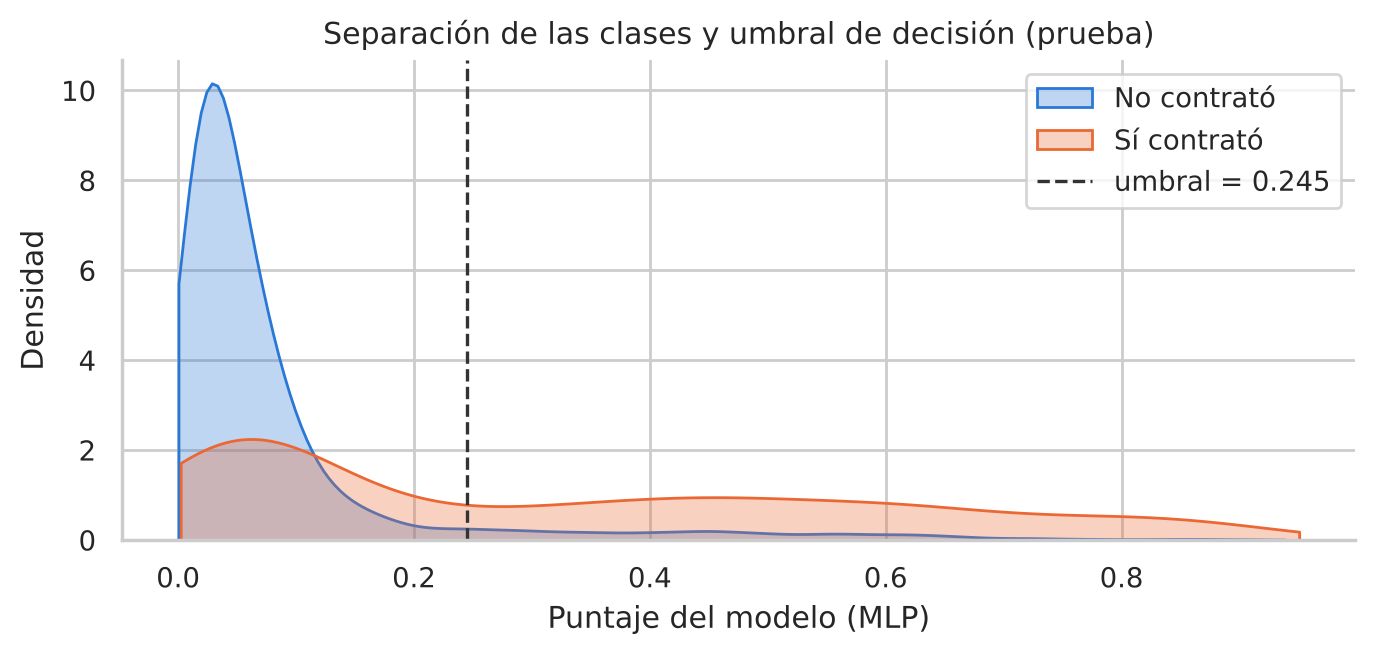

In [32]:
fig, ax = plt.subplots(figsize=(7, 3.4))
for k, nombre, c in [(0, "No contrató", "#2a78d6"), (1, "Sí contrató", "#eb6834")]:
    sns.kdeplot(res.loc[res.real == k, "puntaje"], ax=ax, fill=True, alpha=0.3, color=c, label=nombre, cut=0)
ax.axvline(umbrales[mejor_modelo], color="#333", ls="--", lw=1.2, label=f"umbral = {umbrales[mejor_modelo]:.3f}")
ax.set_xlabel(f"Puntaje del modelo ({mejor_modelo})"); ax.set_ylabel("Densidad")
ax.set_title("Separación de las clases y umbral de decisión (prueba)")
ax.legend()
guardar_fig("fig10_errores_puntaje")
plt.show()

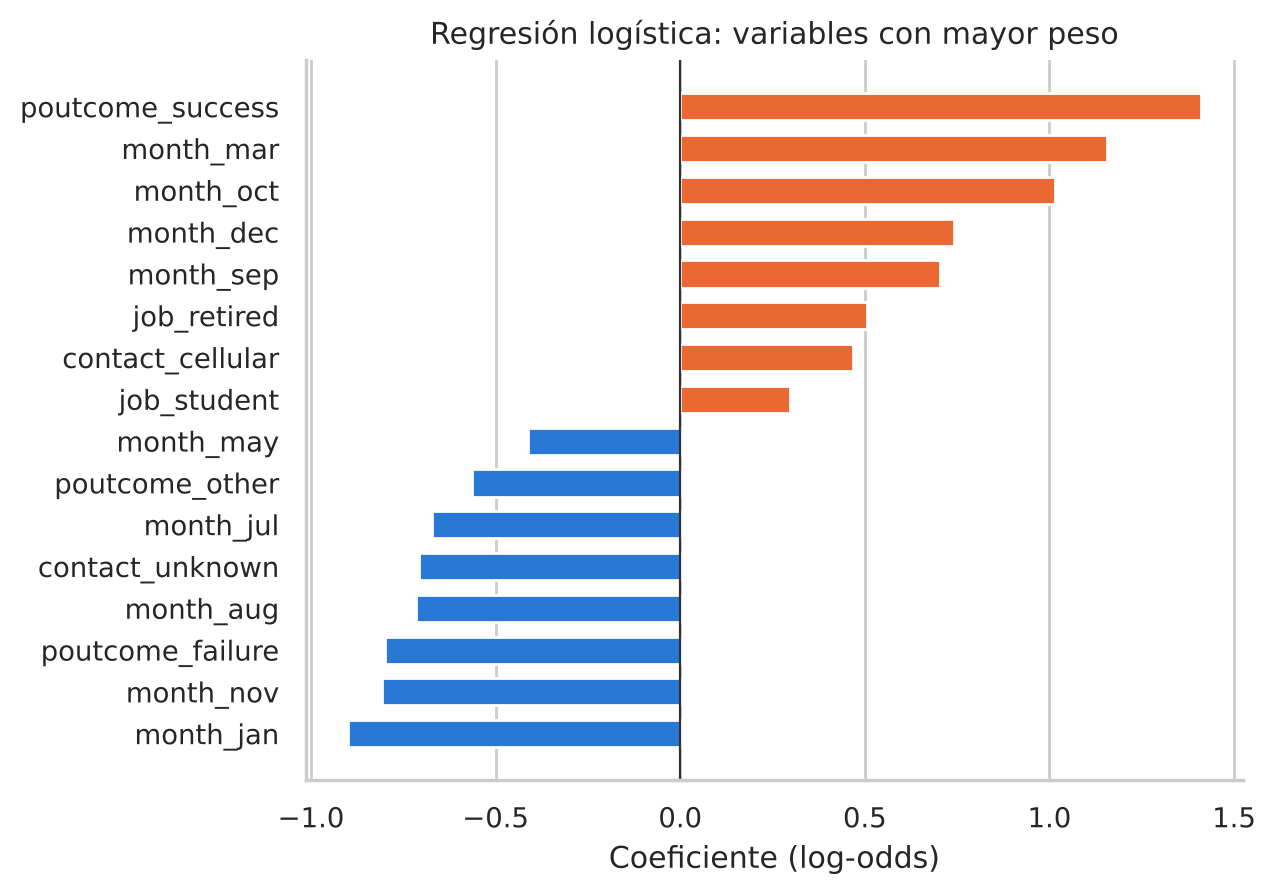

In [33]:
# Variables con más peso en la regresión logística (coeficientes sobre datos escalados / one-hot)
rl = finales["Regresión logística"]
nombres_col = rl.named_steps["prep"].get_feature_names_out()
coef = pd.Series(rl.named_steps["modelo"].coef_[0], index=[c.split("__")[1] for c in nombres_col]).sort_values()
top = pd.concat([coef.head(8), coef.tail(8)])
fig, ax = plt.subplots(figsize=(6.5, 4.6))
ax.barh(top.index, top.values, color=np.where(top.values > 0, "#eb6834", "#2a78d6"), height=0.65)
ax.axvline(0, color="#333", lw=0.8)
ax.set_xlabel("Coeficiente (log-odds)"); ax.set_title("Regresión logística: variables con mayor peso")
ax.grid(axis="y", visible=False)
guardar_fig("fig11_coeficientes")
plt.show()
coef.round(3).to_csv("resultados/coeficientes_regresion_logistica.csv")

**Interpretación.**
- **Hay un núcleo de casos difíciles:** 466 de los 1 058 clientes que sí contrataron (44 %) **ningún modelo** los detecta. Con la información disponible antes de la llamada, esos clientes son indistinguibles de los que no contratan; solo `duration`, que no se puede usar, los revelaría.
- **El historial previo domina:** con `poutcome = success` el modelo detecta al 98.5 % de los que contratan. Con `poutcome = unknown` (clientes nuevos, el 82 % de la cartera) la sensibilidad cae a **33.9 %**. El modelo funciona bien con clientes conocidos y mal con los nuevos.
- **`contact = unknown`:** la sensibilidad es de apenas **3.8 %**. Casi nunca predice "sí" en ese grupo, porque su tasa real de éxito es muy baja (4 %).
- **Edad:** los mayores de 60 tienen una tasa de éxito alta (41 %) y el modelo los detecta bien (88 %). El grupo de 31 a 45 años, el más numeroso, es el más difícil (43 %).
- **Distribución de puntajes:** los no contratantes se concentran en puntajes bajos, pero los que sí contratan se reparten en todo el rango. Muchos quedan por debajo del umbral, mezclados con la clase mayoritaria; esa es la zona de falsos negativos.
- **Coeficientes de la regresión logística:** confirman el EDA. Aumentan la probabilidad un éxito previo, contactar en marzo, octubre, diciembre o septiembre, ser jubilado o estudiante y el contacto por celular. La disminuyen contactar en enero, noviembre, agosto, julio o mayo, un fracaso previo y el contacto desconocido.

## 8. Resultados finales y conclusiones

In [34]:
final = tabla_prueba[["Exactitud", "Exactitud balanceada", "Precisión", "Sensibilidad", "F1", "AUC-ROC", "AP"]].round(4)
final["F1 IC 95 %"] = tabla_boot["F1"].str.extract(r"(\[.*\])")[0]
final.to_csv("resultados/tabla_final.csv")
print("Archivos generados:")
for d in ["figuras", "resultados"]:
    for f in sorted(os.listdir(d)):
        print(f"  {d}/{f}")
final

Archivos generados:
  figuras/fig01_desbalance.png
  figuras/fig02_numericas.png
  figuras/fig03_categoricas.png
  figuras/fig04_correlacion.png
  figuras/fig05_svm_malla.png
  figuras/fig06_mlp_entrenamiento.png
  figuras/fig07_matrices_confusion.png
  figuras/fig08_roc_pr.png
  figuras/fig09_bootstrap_f1.png
  figuras/fig10_errores_puntaje.png
  figuras/fig11_coeficientes.png
  figuras/fig12_ganancia.png
  resultados/ajuste_hiperparametros.csv
  resultados/coeficientes_regresion_logistica.csv
  resultados/comparaciones_mcnemar.csv
  resultados/ganancia_acumulada.csv
  resultados/intervalos_bootstrap.csv
  resultados/metricas_prueba.csv
  resultados/mlp_arquitectura.csv
  resultados/mlp_semillas.csv
  resultados/nb_intervalos_alpha.csv
  resultados/perfil_errores.csv
  resultados/tabla_final.csv
  resultados/umbrales_validacion.csv


,Exactitud,Exactitud balanceada,Precisión,Sensibilidad,F1,AUC-ROC,AP,F1 IC 95 %
Modelo,,,,,,,,
Regresión logística,0.8621,0.6854,0.4179,0.4546,0.4355,0.7681,0.4061,"[0.411, 0.463]"
Naive Bayes,0.8667,0.6650,0.4263,0.4017,0.4136,0.7607,0.3896,"[0.387, 0.441]"
SVM,0.8662,0.6946,0.4338,0.4707,0.4515,0.7781,0.4047,"[0.428, 0.478]"
MLP,0.8735,0.7135,0.4627,0.5047,0.4828,0.7856,0.4353,"[0.458, 0.508]"


### Conclusiones

1. **Preparación.** Se eliminó `duration` por fuga de información, se conservó `unknown` como categoría informativa, se creó `contactado_antes` y todo el preprocesamiento (one-hot, escalado y discretización) se ajustó dentro de *pipelines*, solo con datos de entrenamiento.
2. **Desbalance.** Con 11.7 % de positivos, la exactitud es engañosa: ningún modelo supera el 88.3 % trivial. Se usaron AP para el ajuste y F1 con un **umbral elegido en validación** para la decisión final.
3. **Modelos.** El **MLP es el mejor** (F1 = 0.483, AP = 0.435, AUC = 0.786) y su ventaja es estadísticamente significativa según el bootstrap pareado y McNemar. A diferencia de conjuntos pequeños y casi lineales, aquí el volumen de datos (27 000 registros) permite a la red aprovechar **interacciones** entre variables como mes, tipo de contacto e historial. La SVM quedó en segundo lugar, limitada por su costo computacional. Naive Bayes categórico fue el más débil, aunque superó claramente a su variante gaussiana.
4. **Valor práctico.** Llamando solo a los clientes que el MLP marca como "sí" (13 % de la cartera de prueba), se encuentra a la mitad de los interesados con una tasa de éxito de 46 %, cuatro veces la de una campaña sin selección.
5. **Limitaciones y trabajo futuro.** El 44 % de los contratantes no es detectable con la información previa a la llamada. Se propone incorporar las variables socioeconómicas de la versión `bank-additional`, entrenar la SVM con aproximaciones de kernel (Nyström) para usar todos los datos, probar modelos de ensamble (*gradient boosting*) y evaluar con **validación temporal**, porque los datos están ordenados de mayo de 2008 a noviembre de 2010.